# Demand Calculations
In this notebook, we calculate state level demand for each byproduct across its key marketable end-uses.

In [143]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from cmcrameri import cm

from molmass import Formula

# add main repo directory to path
import sys
import os
sys.path.append(os.path.abspath('..'))

# add submodules to path
sys.path.append('../submodules/gw-avail-and-comp')

# set up figure style in same way as gw-avail-and-comp repo
from project_utils import setup_figure_style, subscript_numbers, get_boundaries
setup_figure_style()

# Load Data

In [144]:
# state geodataframe
st_df = get_boundaries('state')
st_df.drop(index=st_df[st_df['STUSPS']=='DC'].index, inplace=True)
st_df = st_df.sort_values(by='NAME').reset_index(drop=True)

In [145]:
# load market data
market_path = '../data/byproduct_markets.xlsx'
market_df = pd.read_excel(market_path, na_values=['-'])

# collapse by end use category
market_df = market_df.groupby(['byproduct', 'end_use_category'], as_index=False).agg({'pct_of_demand': lambda x: x.sum(skipna=False)})
market_df.head(2)

,byproduct,end_use_category,pct_of_demand
0,B,Insulation Fiberglass Manufacturing,0.65
1,B,Miscellaneous Manufacturing,0.35


In [146]:
# load proxy metrics
proxy_path = '../data/disaggregation_proxies.xlsx'
proxy_dict = pd.read_excel(proxy_path, sheet_name=None, header=3, usecols='B:E', nrows=48)

# identify proxies to be used for each end use category
market_to_proxy_dict = {
    'Insulation Fiberglass Manufacturing' : 'mineral_wool',
    'Miscellaneous Manufacturing' : 'manufacturing',
    'Oil and Gas Drilling' : 'oil_and_gas_wells',
    'Miscellaneous Industrial' : 'industrial_energy_consumption',
    'Miscellaneous Chemical Manufacturing' : 'chemical_manufacturing',
    'Organic Chemical Manufacturing' : 'org_chemical_manufacturing',
    'Pharmaceutical Manufacturing' : 'pharma_manufacturing',
    'Industrial Water Treatment' : 'industrial_water_use',
    'Soil Additive' : 'crop_acreage',
    'Lime Manufacturing' : 'lime_manufacturing',
    'Flue Gas Desulfurization' : 'flue_gas_desulfurization',
    'Cement Manufacturing' : 'cement_production',
    'Hydrofluoric Acid Production' : 'hf_production_capacity',
    'Drinking Water Treatment' : 'public_supply_water_use',
    'Wastewater Treatment' : 'wwtp_flow',
    'Pulp and Paper Manufacturing' : 'pulp_and_paper_facilities',
    'Iron and Steel Manufacturing' : 'iron_and_steel_employment',
    'Miscellaneous Metallurgy' : 'metallurgy_employment',
    'Miscellaneous Construction' : 'construction_spending',
    'Gypsum-Based Product Manufacturing' : 'gypsum_facilities',
    'Miscellaneous Fertilizer Application' : 'crop_acreage',
    'Oil and Gas Well Acidification' : 'oil_and_gas_wells',
    'Steel Pickling' : 'steel_pickling_facilities',
    'Semiconductor Manufacturing' : 'semiconductor_employment',
    'Metal Ore Leaching' : 'ore_treated',
    'Nitrogenous Fertilizer Manufacturing' : 'ammonia_production_capacity',
    'Phosphatic Fertilizer Manufacturing' : 'phosphate_fertilizer_facilities',
    'Pesticide Manufacturing' : 'pesticide_employment',
    'Potash Fertilizer Application' : 'potash_fertilizer_consumption',
    'Lithium Battery Manufacturing' : 'lithium_battery_production',
    'Cosmetics and Personal Care Product Manufacturing' : 'cosmetics_employment',
    'Deicing and Dust Control' : 'rock_salt_distribution',
    'Glass Manufacturing' : 'glass_emissions',
    'Alumina Refining' : 'alumina_refining_capacity',
    'Nitrogenous Fertilizer Application' : 'nitrogen_fertilizer_consumption',
    'Phosphoric Acid Manufacturing' : 'phosphoric_acid_facilities',
}

print('Proxies by End-Use Category:')
for market, proxy in market_to_proxy_dict.items():
    print(f' - {market}: {proxy}')

print('\nOther Availalbe Proxies:')
for proxy in proxy_dict.keys():
    if proxy not in market_to_proxy_dict.values():
        print(f' - {proxy}')

Proxies by End-Use Category:
 - Insulation Fiberglass Manufacturing: mineral_wool
 - Miscellaneous Manufacturing: manufacturing
 - Oil and Gas Drilling: oil_and_gas_wells
 - Miscellaneous Industrial: industrial_energy_consumption
 - Miscellaneous Chemical Manufacturing: chemical_manufacturing
 - Organic Chemical Manufacturing: org_chemical_manufacturing
 - Pharmaceutical Manufacturing: pharma_manufacturing
 - Industrial Water Treatment: industrial_water_use
 - Soil Additive: crop_acreage
 - Lime Manufacturing: lime_manufacturing
 - Flue Gas Desulfurization: flue_gas_desulfurization
 - Cement Manufacturing: cement_production
 - Hydrofluoric Acid Production: hf_production_capacity
 - Drinking Water Treatment: public_supply_water_use
 - Wastewater Treatment: wwtp_flow
 - Pulp and Paper Manufacturing: pulp_and_paper_facilities
 - Iron and Steel Manufacturing: iron_and_steel_employment
 - Miscellaneous Metallurgy: metallurgy_employment
 - Miscellaneous Construction: construction_spending
 -

# Helper Functions

In [95]:
def calculate_state_demand(bp, market, demand, specificity, resolution, proxy=None, total_withheld=0):
    """
    Calculates the demand for a given byproduct in a given market for all
    states in CONUS using the methods specified in methods_dict. Returns a Series with
    the results.

    Arguments:
    bp : str
        The byproduct for which to calculate demand.
    market : str
        The market for which to calculate demand.
    demand : float or Series
        The demand data provided. If resolution is 'state', this should be a state alpha-indexed 
        Series with the demand for each state. If resolution is 'domestic', this should be a float 
        with the total demand for the US.
    specificity : str
        ('bp' or 'bp-market') The specificity of the demand data provided. If 'bp',
        the demand data is for the byproduct as a whole. If 'bp-market', the demand data
        is for the byproduct in the specified market.
    resolution : str
        ('state' or 'domestic') The resolution of the demand data provided. If 'state', 
        the demand data is for each state individually. If 'domestic', the demand data is
        for the entire US as a whole.
    proxy : str, optional
        The proxy metric to use for disaggregating domestic demand to state-level demand. 
        This is only used if resolution is 'domestic'. Available proxy metrics are keys in
        proxy_dict above. If None, the function will use GDP as a default proxy.
    total_withheld : float, optional
        If resolution is 'state', this is the total demand for the US that is withheld from the state-level data.
        This value will be disaggregated among states whose demand is 'None' using the specified proxy metric.
    
    Returns:
    state_demand : pd.Series
        A Series with the estimated state-level demand for the byproduct in the specified market.
    
    """
    # check that specificity and resolution are valid
    if specificity not in ['bp', 'bp-market']:
        raise ValueError("specificity must be 'bp' or 'bp-market'")
    if resolution not in ['state', 'domestic']:
        raise ValueError("resolution must be 'state' or 'domestic'")
    
    # check that demand is a float if resolution is 'domestic'
    if resolution == 'domestic' and not isinstance(demand, (float, int)):
        raise ValueError("demand must be a float if resolution is 'domestic'")

    # if specificity is 'bp', multiply by market share to get market-specific demand
    if specificity == 'bp':
        market_share = market_df[(market_df['byproduct'] == bp) & (market_df['end_use_category'] == market)]['pct_of_demand'].values[0]
        demand = demand * market_share
    
    # if resolution is 'domestic', disaggregate to state level using proxy
    if resolution == 'domestic':
        if proxy is None:
            proxy = 'GDP'
        if proxy not in proxy_dict.keys():
            raise ValueError(f"proxy must be one of {list(proxy_dict.keys())}")
        proxy_df = proxy_dict[proxy]
        proxy_df = proxy_df.set_index('State Alpha')
        state_demand = proxy_df['Percent of Total'] * demand
    
    # if resolution is 'state', impute withheld demand for states with missing data using proxy
    else:
        if total_withheld > 0:
            if proxy is None:
                proxy = 'GDP'
            if proxy not in proxy_dict.keys():
                raise ValueError(f"proxy must be one of {list(proxy_dict.keys())}")
            proxy_df = proxy_dict[proxy]
            proxy_df = proxy_df.set_index('State Alpha')
            states_without_data = [st for st, d in demand.items() if np.isnan(d)]
            w_proxy_df = proxy_df.loc[states_without_data].copy() # isolate states with withheld dat
            w_proxy_df['Percent of Total'] = w_proxy_df['Metric Value'] / w_proxy_df['Metric Value'].sum() # recalculate percent of total for states with withheld data
            for state in states_without_data:
                demand.loc[state] = w_proxy_df.loc[state, 'Percent of Total'] * total_withheld
        
        state_demand = demand
    
    # rename series
    state_demand.name = 'demand_kt'
    
    return state_demand

In [96]:
demand_dict = {}

In [97]:
# market = ''
# demand = # kt
# specificity = '' # ('bp' or 'bp-market')
# resolution = '' # ('state' or 'domestic')
# proxy = market_to_proxy_dict[market]

# state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
# demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# # plot map of state-level demand
# fig, ax = plt.subplots(figsize=(4,2))
# ax.axis('off')
# st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
# st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
# ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Boron (B)

In [98]:
bp = 'B'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for B:
 - Insulation Fiberglass Manufacturing (65.0%)
 - Miscellaneous Manufacturing (35.0%)


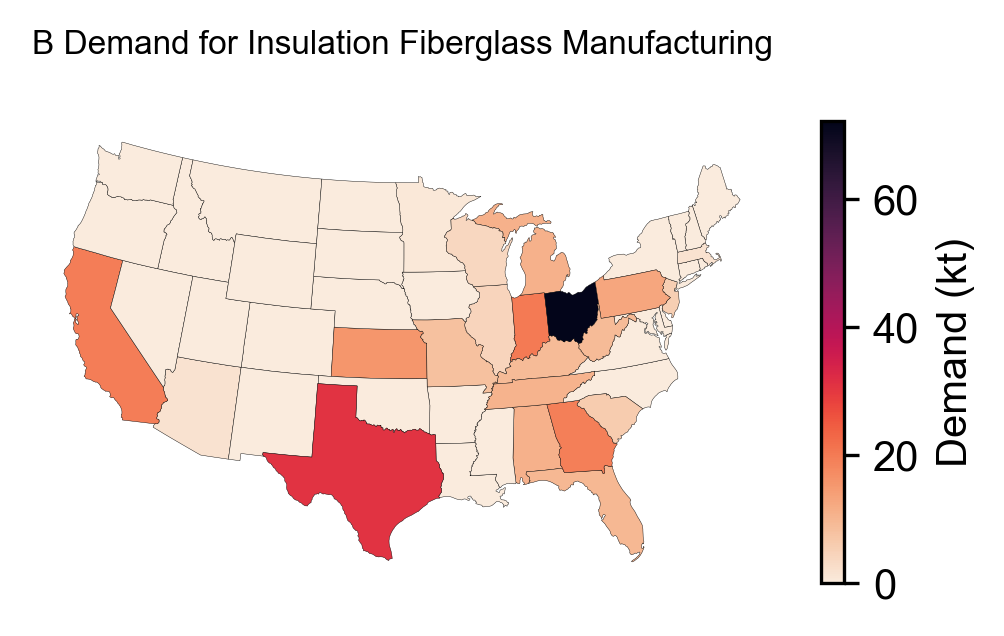

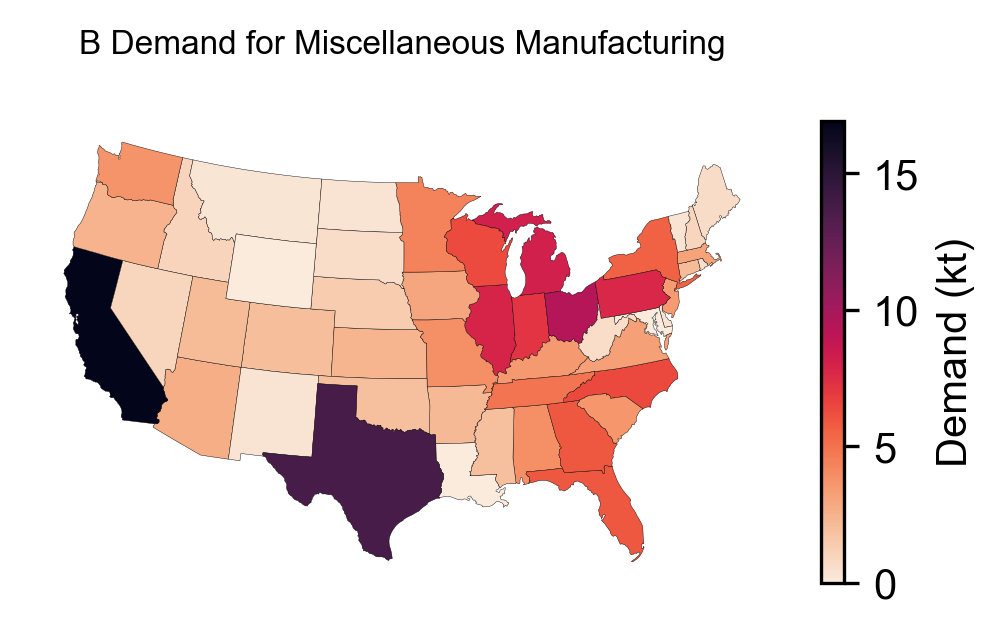

In [99]:
demand = 500 # kt
specificity = 'bp'
resolution = 'domestic'
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Barite (BaSO4)

In [100]:
bp = 'BaSO4'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for BaSO4:
 - Miscellaneous Industrial (10.0%)
 - Oil and Gas Drilling (90.0%)


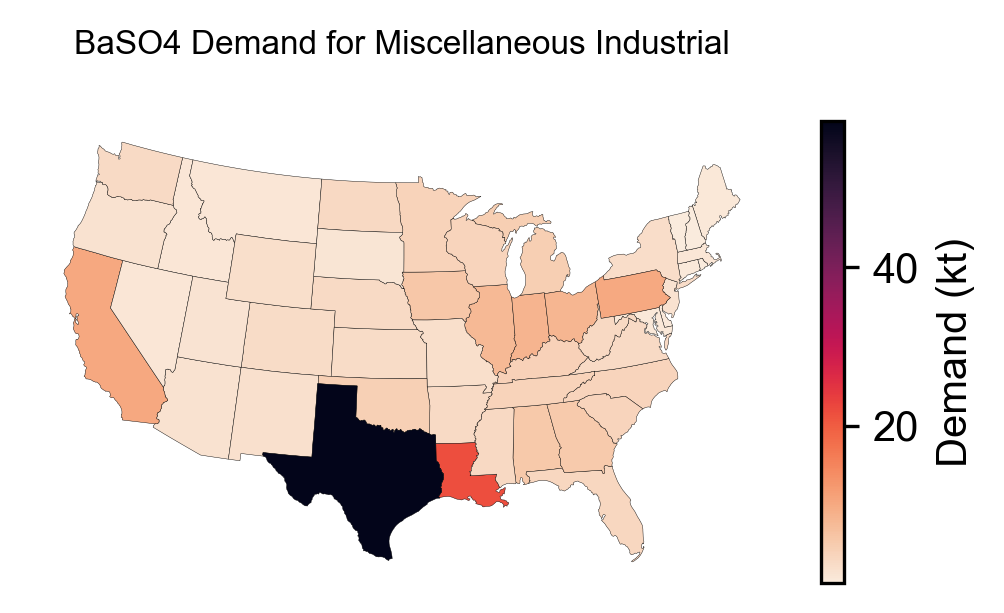

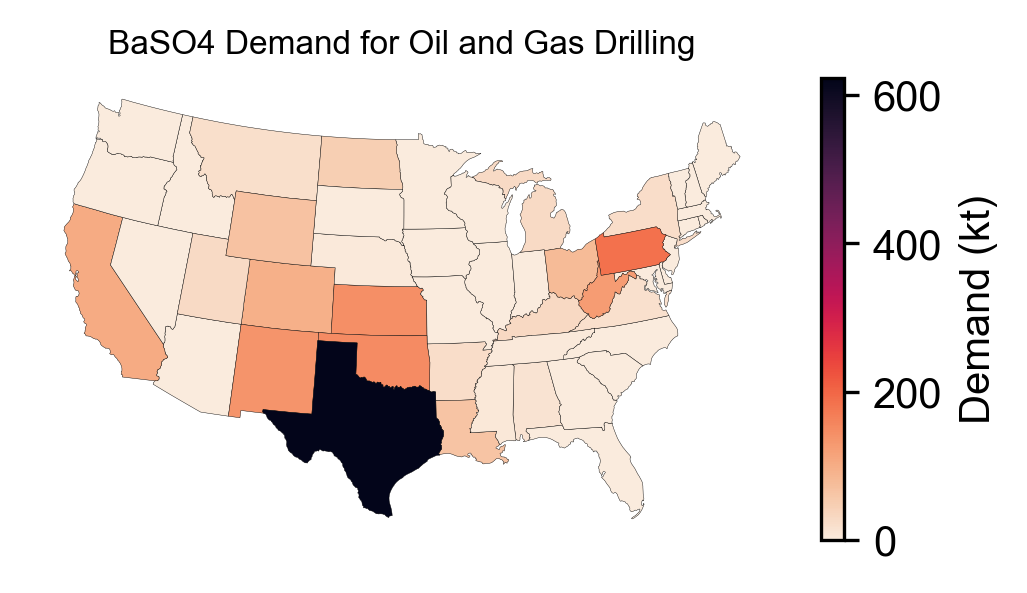

In [101]:
demand = 2260 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Bromine (Br)

In [102]:
bp = 'Br'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for Br:
 - Industrial Water Treatment (8.4%)
 - Miscellaneous Chemical Manufacturing (58.9%)
 - Oil and Gas Drilling (12.6%)
 - Organic Chemical Manufacturing (10.5%)
 - Pharmaceutical Manufacturing (9.5%)


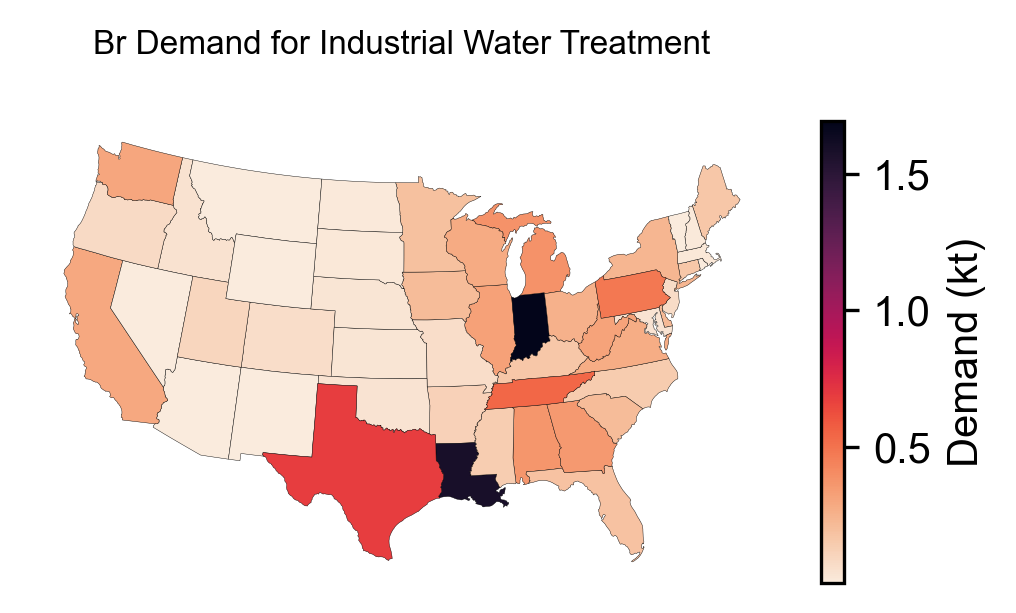

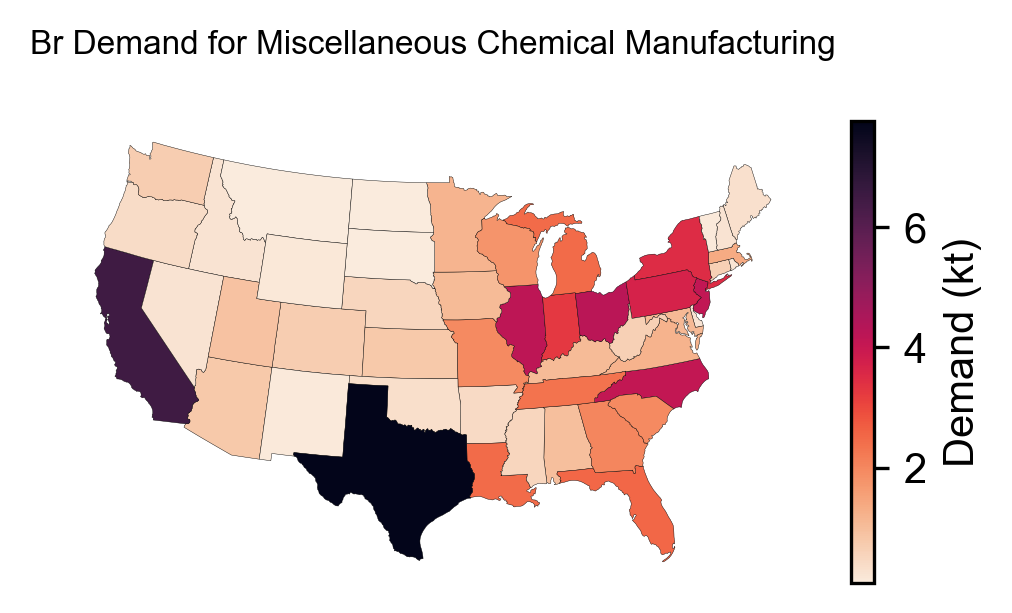

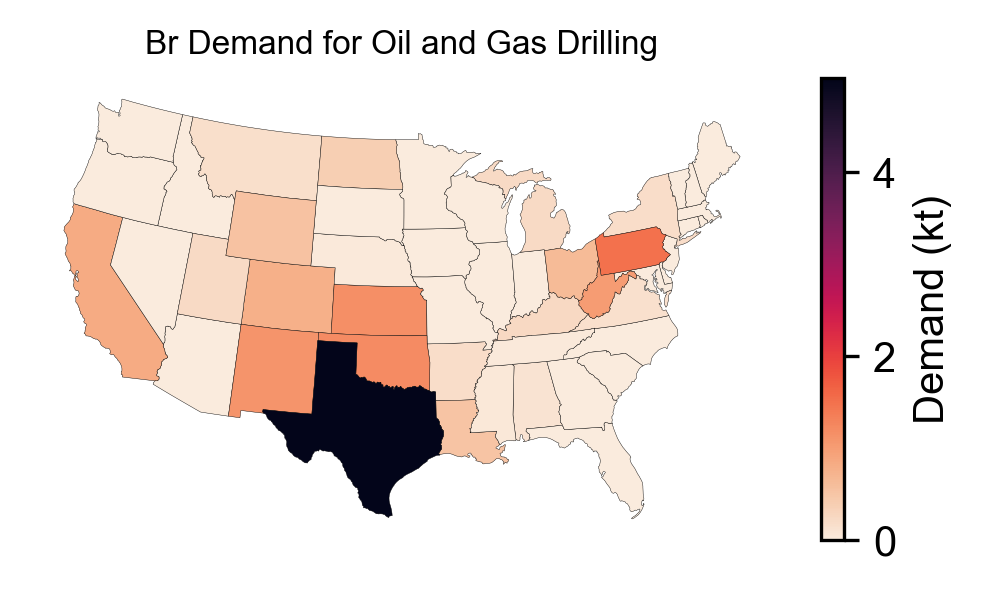

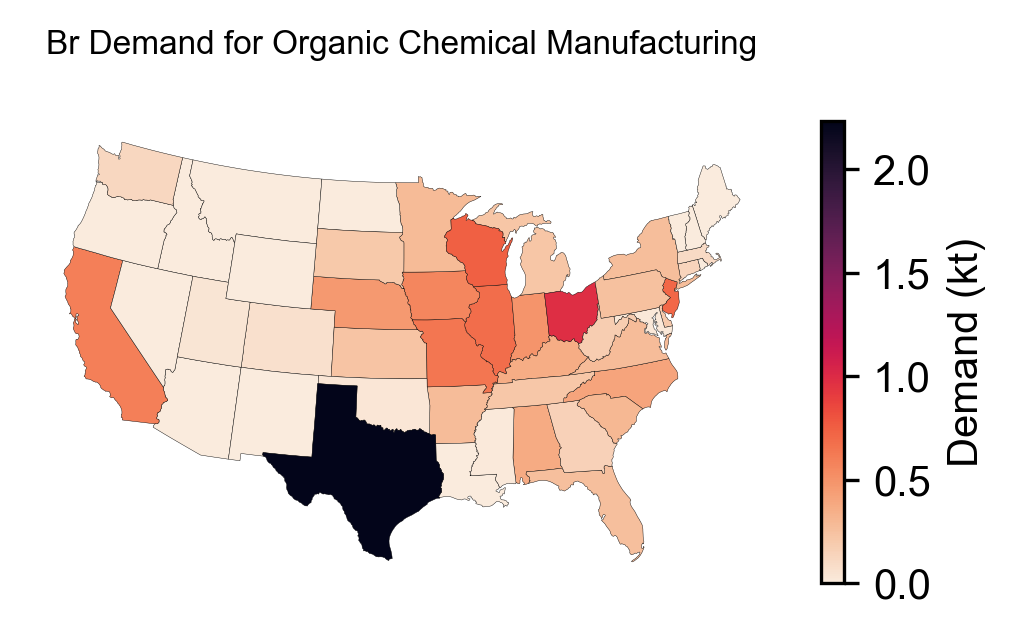

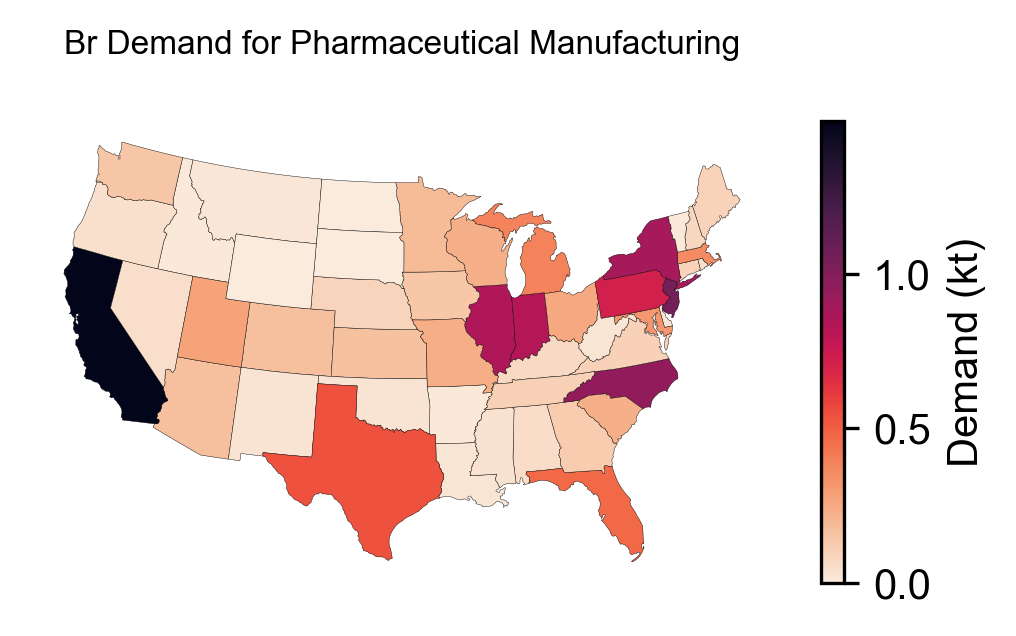

In [103]:
demand =  130 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Calcium Carbonate (CaCO3)

In [104]:
bp = 'CaCO3'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for CaCO3:
 - Cement Manufacturing (nan%)
 - Flue Gas Desulfurization (nan%)
 - Lime Manufacturing (nan%)
 - Soil Additive (nan%)


Text(0.5, 1.0, 'CaCO3 Demand for Cement Manufacturing')

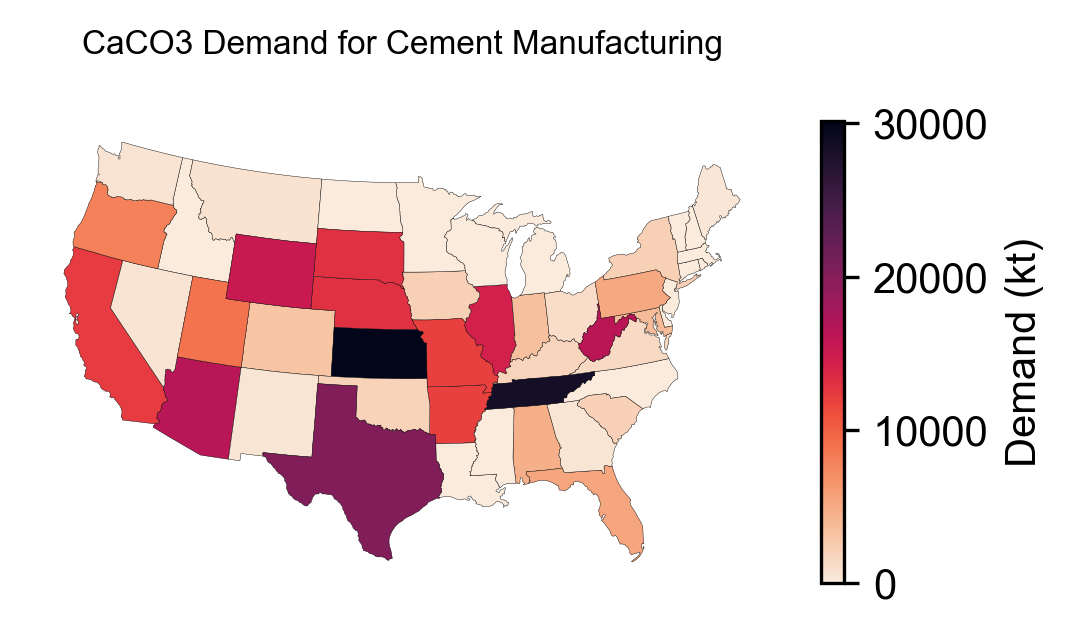

In [105]:
market = 'Cement Manufacturing'
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'state' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

# build state-level demand data series
# where available, use state level demand data for end use as reported
demand = dict.fromkeys(st_df['STUSPS'], np.nan)
demand.update({ # (kt)
    'AL': 4660,
    'CA': 12300,
    'CO': 3140,
    'CT': 0,
    'DE': 0,
    'FL': 5370,
    'GA': 530,
    'ID': 0,
    'IN': 3520,
    'IA': 2150,
    'KY': 1770,
    'LA': 0,
    'ME': 394,
    'MD': 3660,
    'MA': 0,
    'MN': 0,
    'MS': 0,
    'MO': 11900,
    'MT': 718,
    'NV': 599,
    'NM': 514,
    'NY': 2150,
    'OH': 1140,
    'OK': 1890,
    'PA': 5190,
    'RI': 0,
    'SC': 2060,
    'TX': 20300,
    'VA': 1460,
    'WA': 637,
    'WI': 0,    
})
demand = pd.Series(demand)
total_withheld = 176000 # kt not disclosed due to proprietary information

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy, total_withheld=total_withheld)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)


Text(0.5, 1.0, 'CaCO3 Demand for Flue Gas Desulfurization')

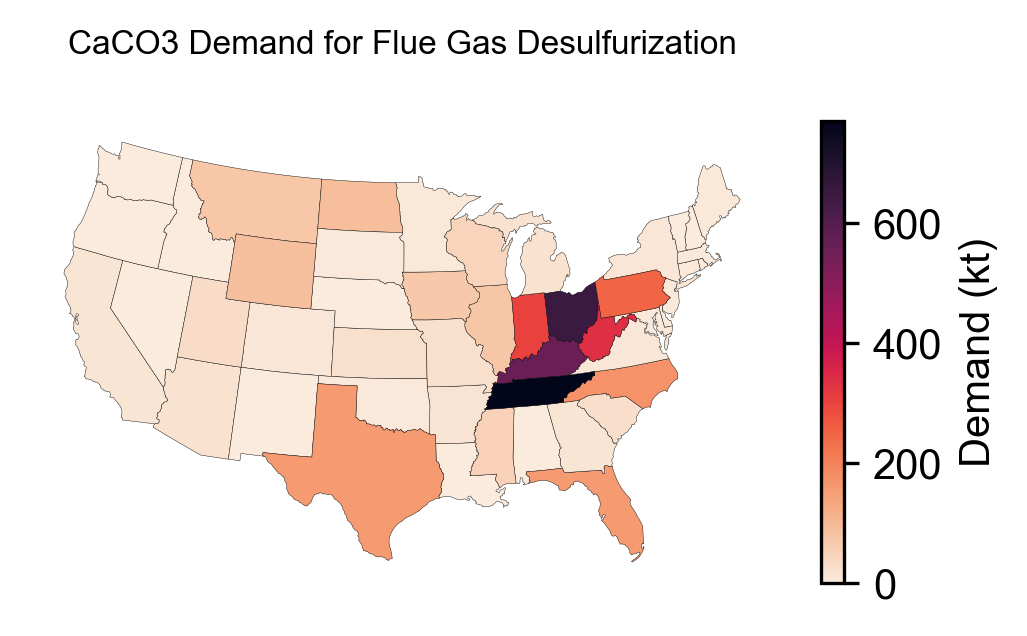

In [106]:
market = 'Flue Gas Desulfurization'
demand = 4120 # kt
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)

Text(0.5, 1.0, 'CaCO3 Demand for Lime Manufacturing')

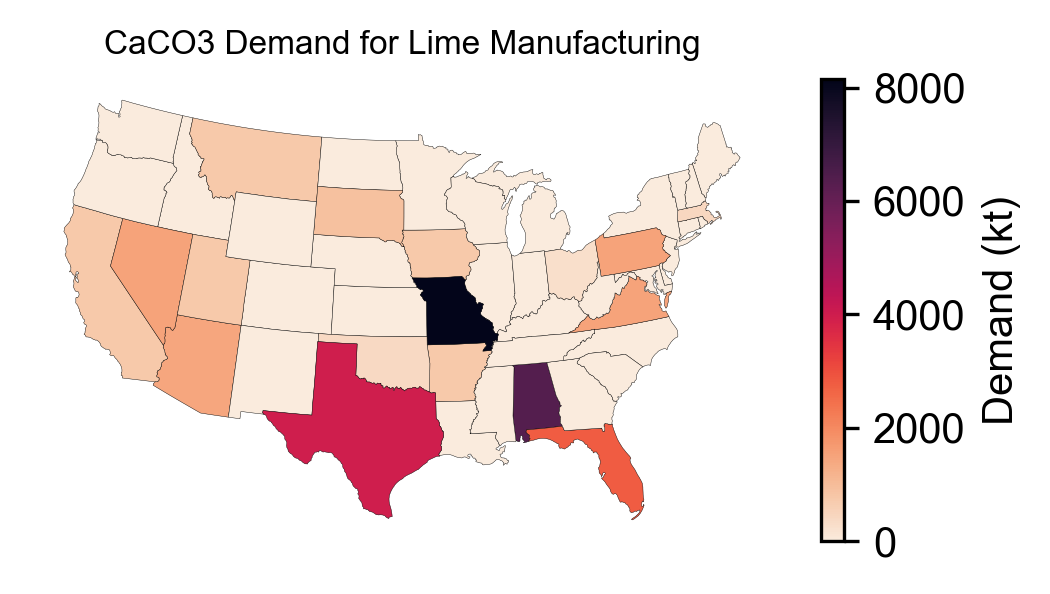

In [107]:
market = 'Lime Manufacturing'
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'state' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

# build state-level demand data series
# where available, use state level demand data for end use as reported
demand = dict.fromkeys(st_df['STUSPS'], np.nan)
demand.update({ # (kt)
    'AL': 6360,
    'AZ': 1440,
    'CO': 0,
    'CT': 0,
    'DE': 0,
    'FL': 2790,
    'GA': 0,
    'ID': 0,
    'IL': 0,
    'IN': 0,
    'KS': 0,
    'KY': 6,
    'LA': 0,
    'ME': 0,
    'MD': 0,
    'MA': 418,
    'MI': 0,
    'MN': 0,
    'MS': 0,
    'MO': 8150,
    'NE': 0,
    'NH': 0,
    'NJ': 0,
    'NM': 0,
    'NY': 0,
    'NC': 0,
    'ND': 0,
    'OH': 255,
    'OK': 395,
    'OR': 0,
    'RI': 0,
    'SC': 0,
    'SD': 895,
    'TN': 0,
    'TX': 3960,
    'VT': 0,
    'WA': 8,
    'WV': 0,
    'WI': 0,
    'WY': 0
})
demand = pd.Series(demand)
total_withheld = 8360 # kt not disclosed due to proprietary information

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy, total_withheld=total_withheld)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)


Text(0.5, 1.0, 'CaCO3 Demand for Soil Additive')

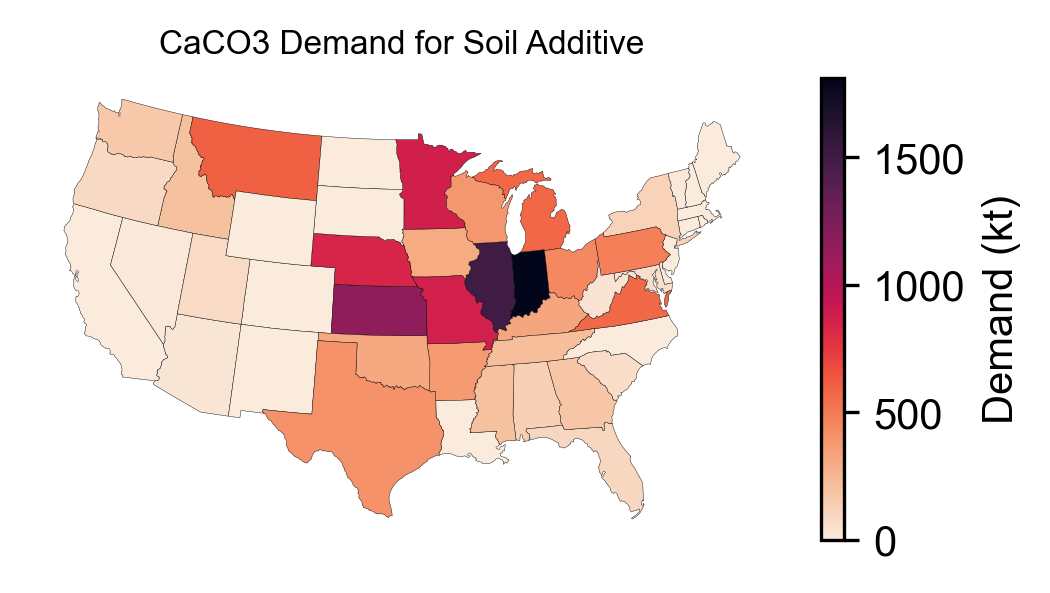

In [108]:
market = 'Soil Additive'
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'state' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

# build state-level demand data series
# where available, use state level demand data for end use as reported
demand = dict.fromkeys(st_df['STUSPS'], np.nan)
demand.update({ # (kt)
    'CA' : 0,
    'CO' : 0,
    'CT' : 2,
    'DE' : 0,
    'IL' : 1500,
    'IN' : 1810,
    'IA' : 297,
    'KY' : 319,
    'LA' : 0,
    'ME' : 0,
    'MA' : 0,
    'MI' : 577,
    'MO' : 863,
    'NH' : 0,
    'NJ' : 0,
    'NM' : 0,
    'NC' : 0,
    'ND' : 0,
    'OK' : 317.47,
    'PA' : 484,
    'RI' : 0,
    'SD' : 0,
    'TX' : 409,
    'VA' : 572,
    'WY' : 0
})
demand = pd.Series(demand)
total_withheld = 6380 # kt not disclosed due to proprietary information

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy, total_withheld=total_withheld)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Fluorspar (CaF2)

In [109]:
bp = 'CaF2'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for CaF2:
 - Hydrofluoric Acid Production (100.0%)


Text(0.5, 1.0, 'CaF2 Demand for Hydrofluoric Acid Production')

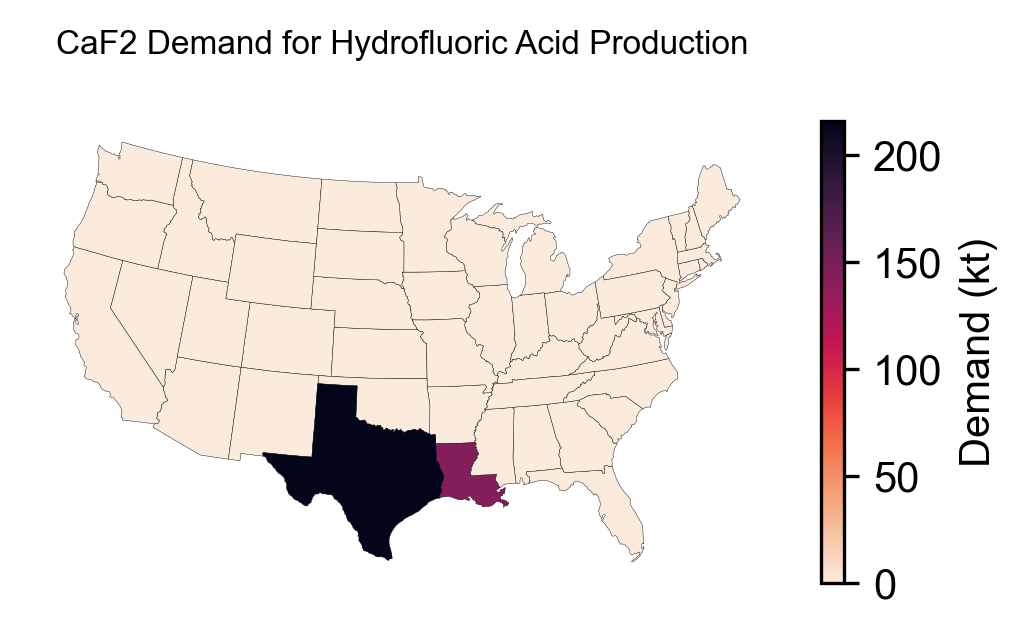

In [110]:
market = 'Hydrofluoric Acid Production'
demand =  360 # kt
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Hydrated Lime (Ca(OH)2)

In [111]:
bp = 'Ca(OH)2'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for Ca(OH)2:
 - Drinking Water Treatment (5.5%)
 - Flue Gas Desulfurization (18.1%)
 - Miscellaneous Chemical Manufacturing (24.9%)
 - Miscellaneous Construction (35.5%)
 - Miscellaneous Metallurgy (2.6%)
 - Other (3.6%)
 - Wastewater Treatment (9.6%)


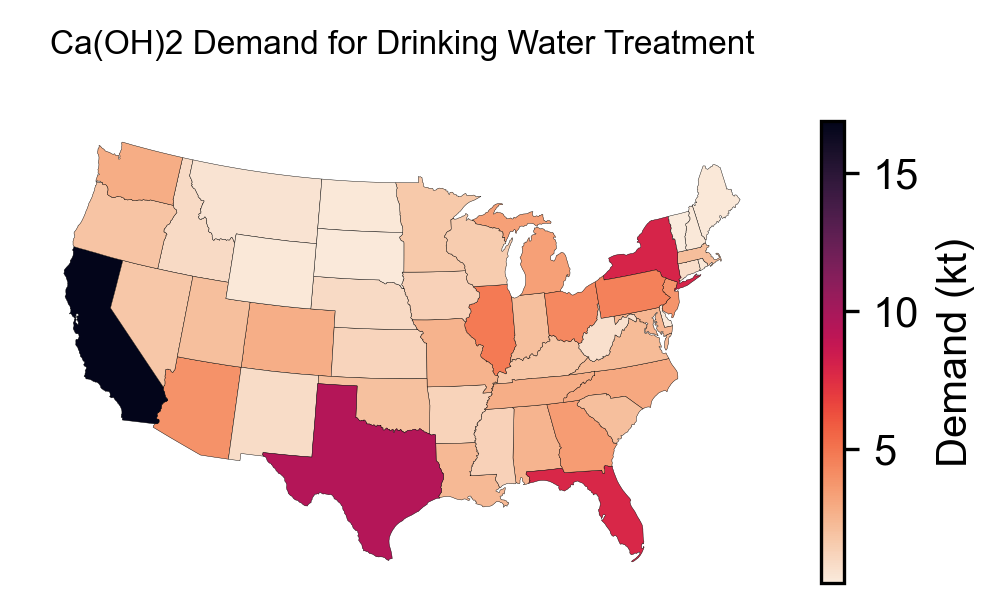

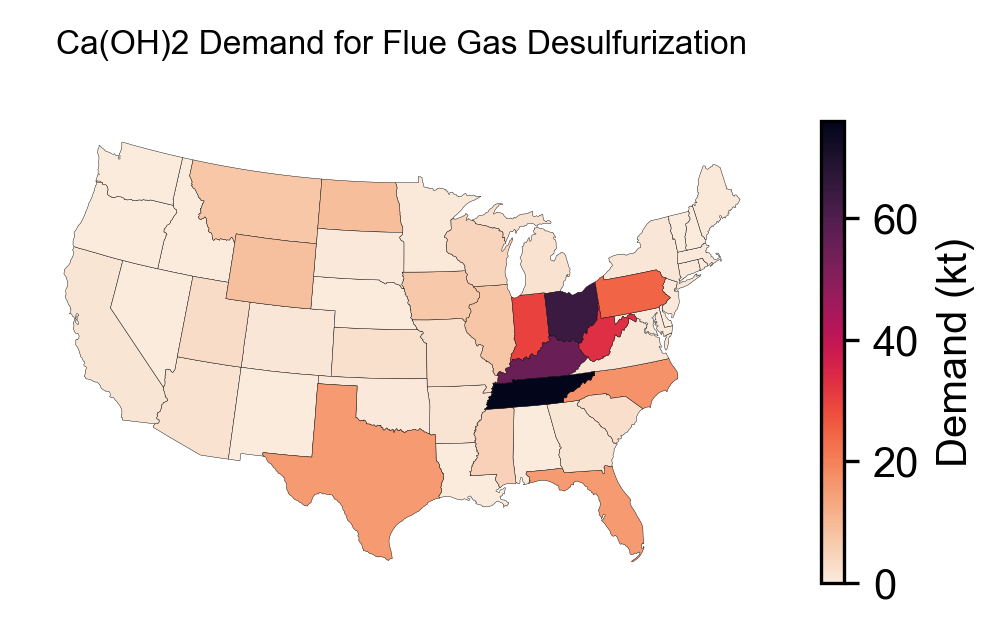

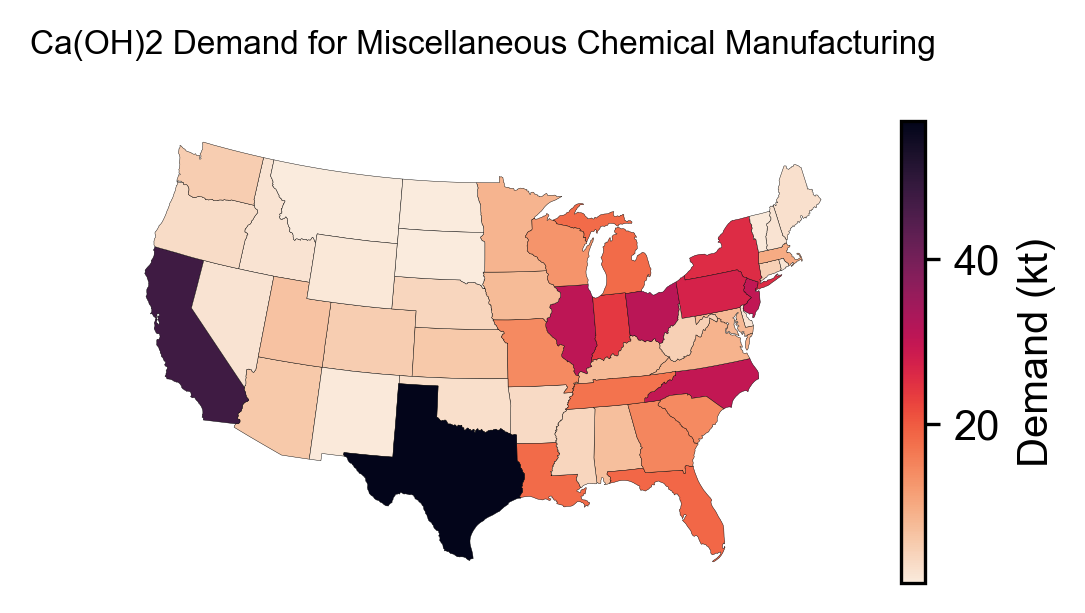

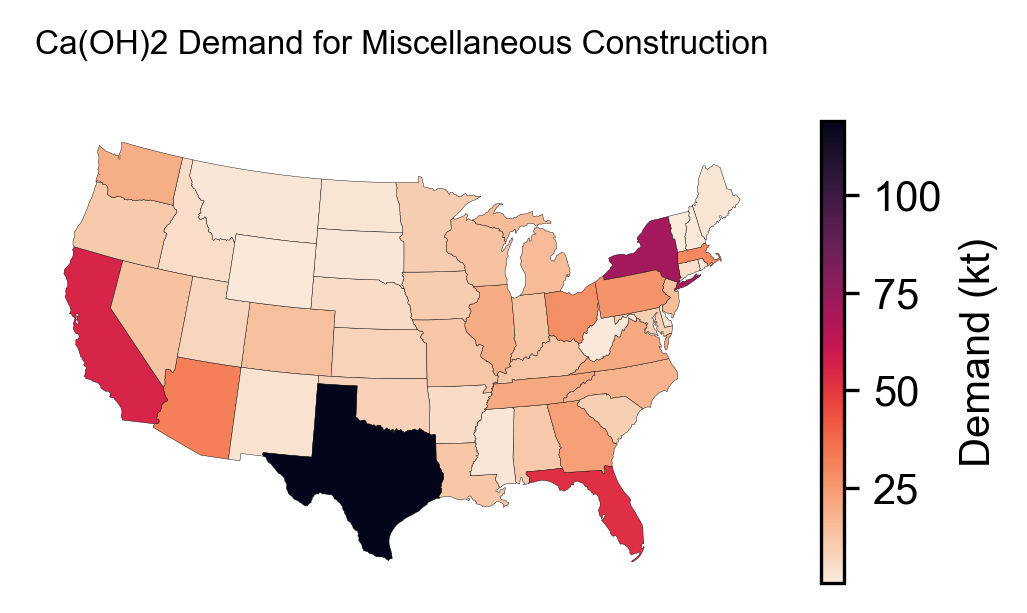

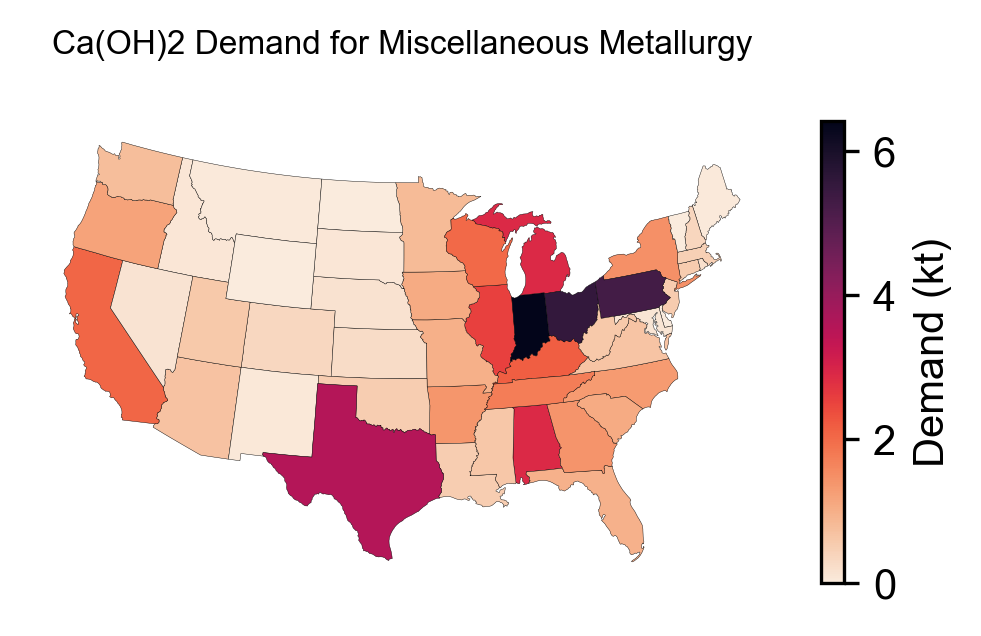

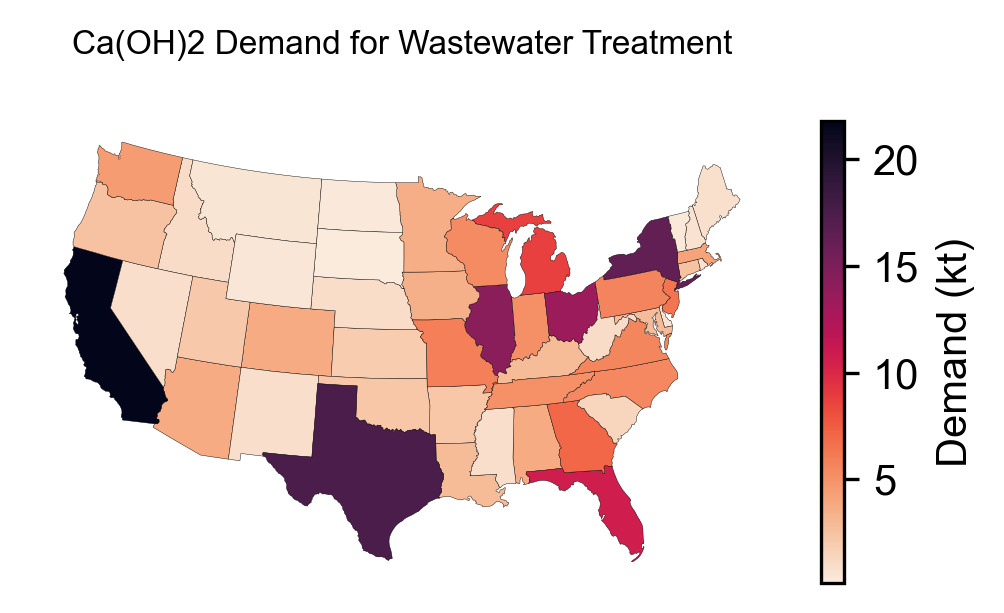

In [112]:
demand =  15000 * 0.15  # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Gypsum (CaSO4)

In [113]:
bp = 'CaSO4'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for CaSO4:
 - Cement Manufacturing (11.9%)
 - Gypsum-Based Product Manufacturing (49.3%)
 - Miscellaneous Fertilizer Application (38.8%)


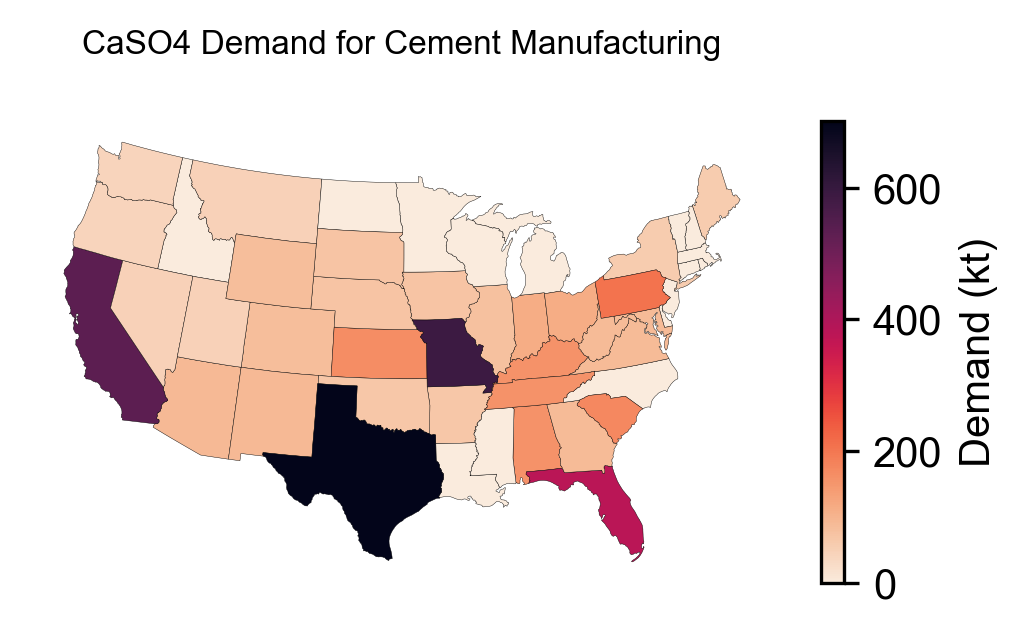

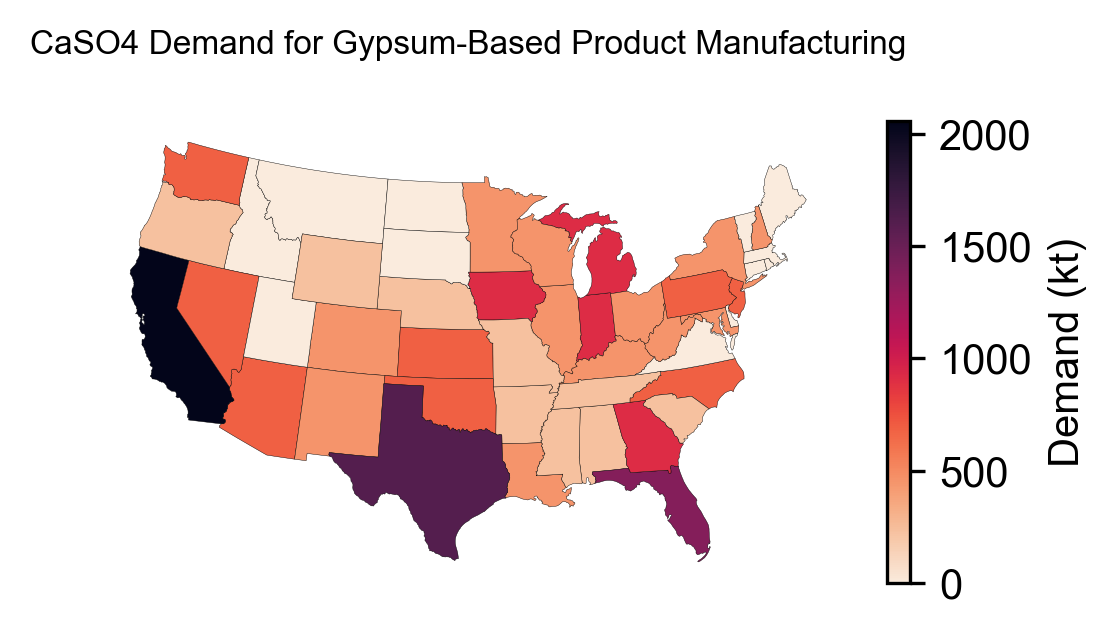

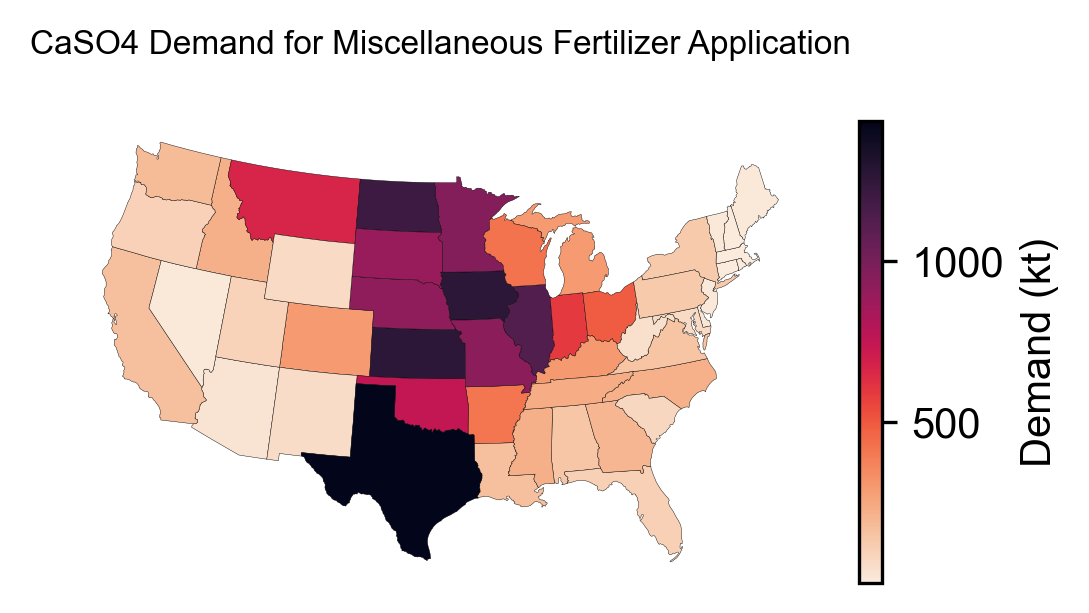

In [114]:
demand = 44000  # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Hydrochloric Acid (HCl)

In [115]:
bp = 'HCl'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for HCl:
 - Miscellaneous Industrial (19.0%)
 - Oil and Gas Well Acidification (30.0%)
 - Other (32.0%)
 - Steel Pickling (19.0%)


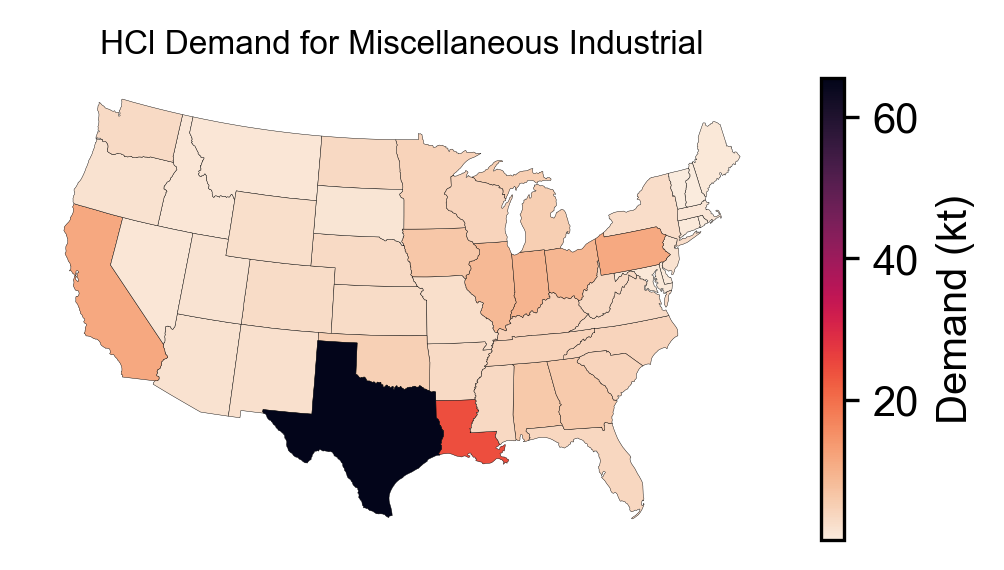

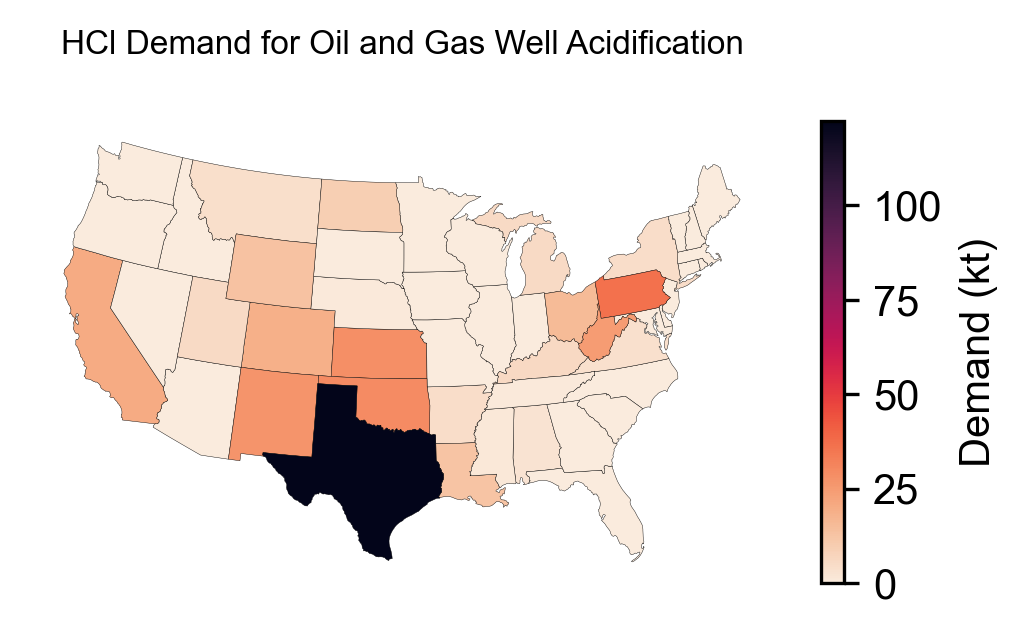

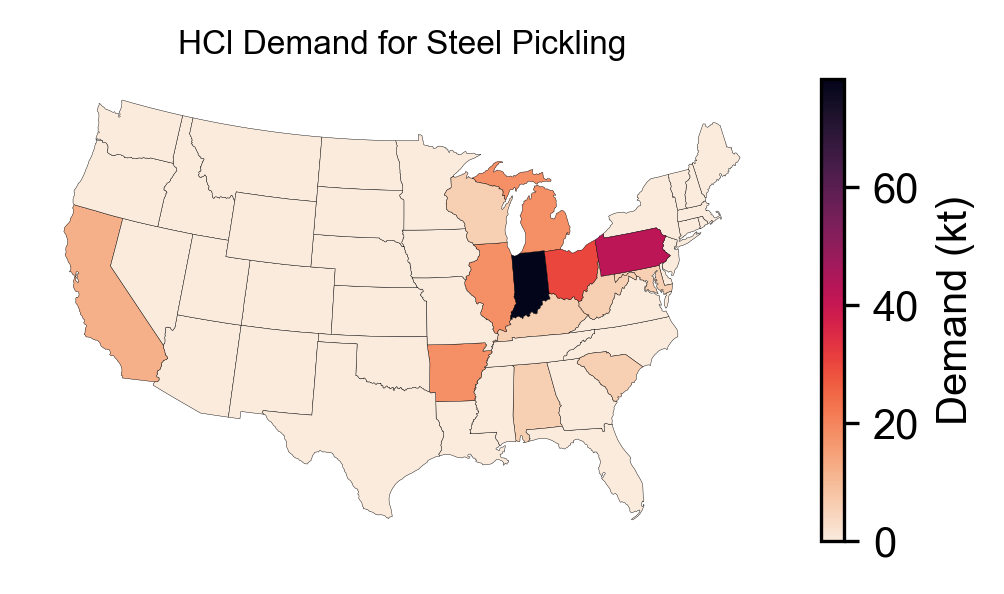

In [116]:
demand = 1332 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Hydrofluoric Acid (HF)

In [117]:
bp = 'HF'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for HF:
 - Organic Chemical Manufacturing (73.1%)
 - Other (10.0%)
 - Semiconductor Manufacturing (5.6%)
 - Steel Pickling (11.4%)


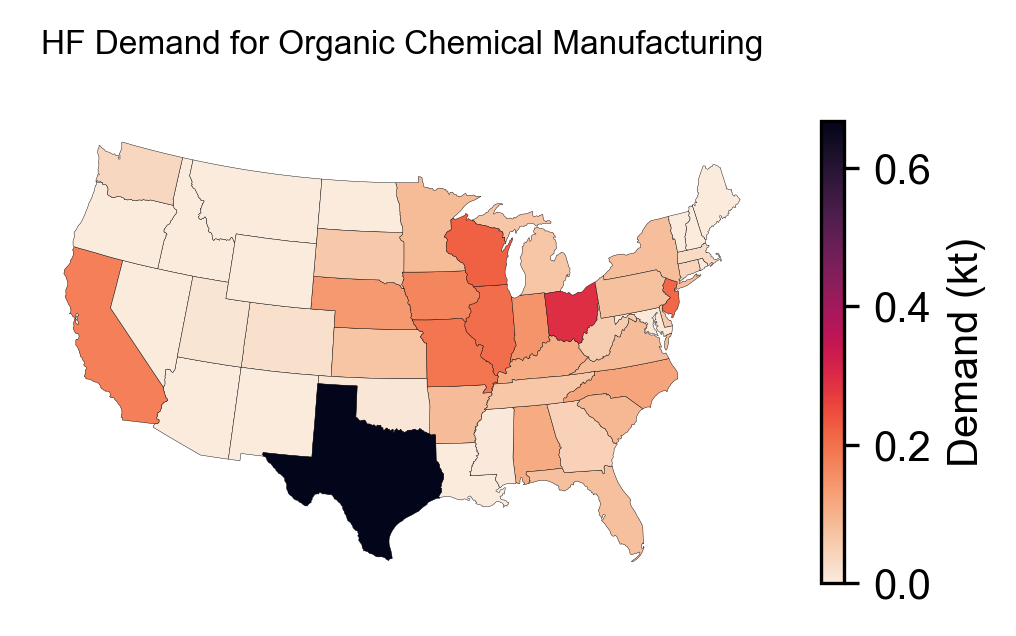

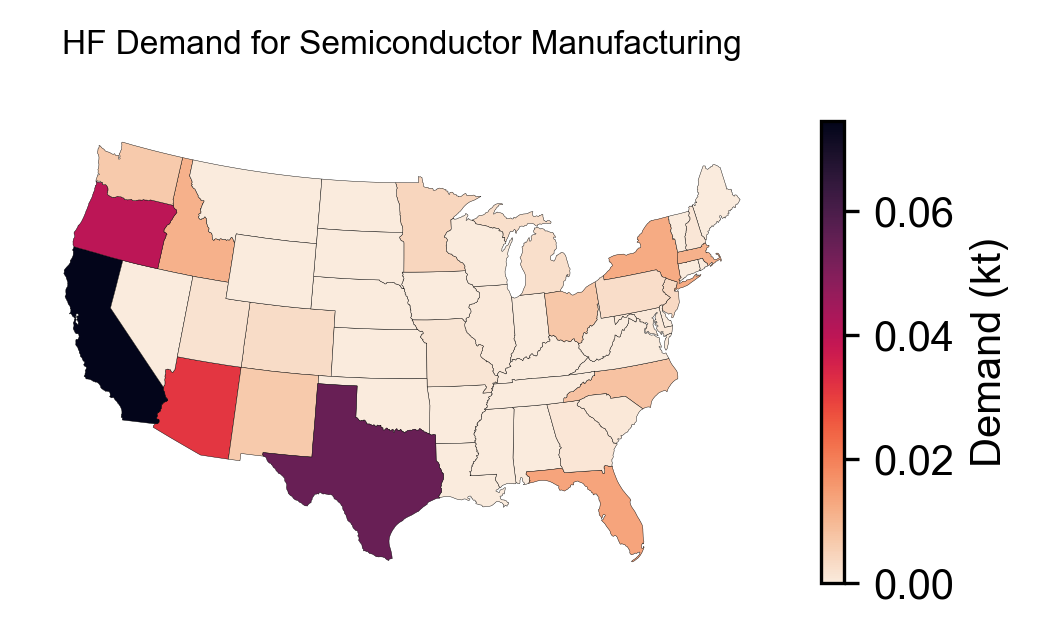

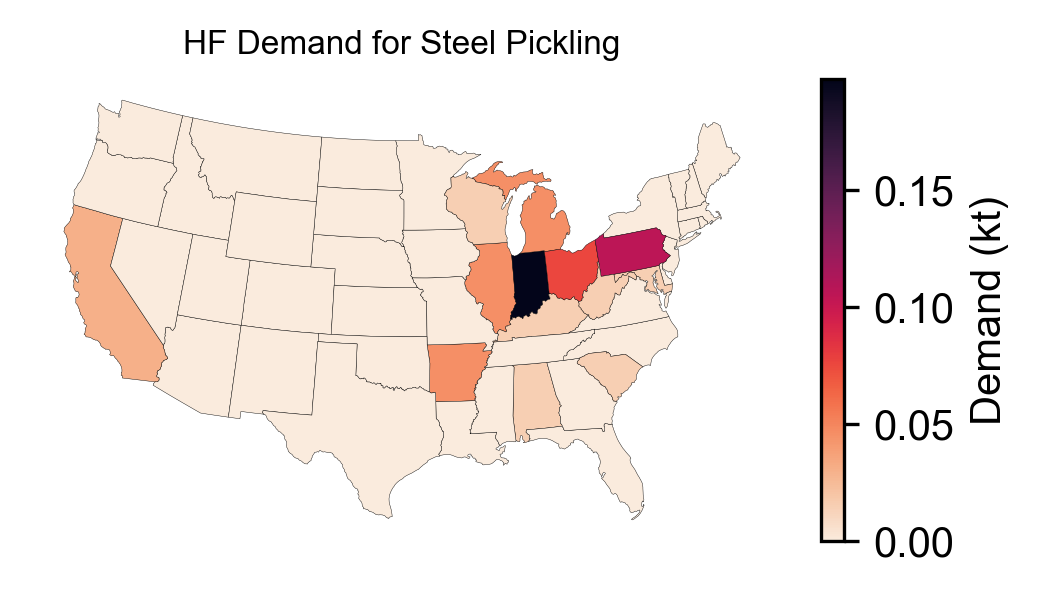

In [118]:
demand = 5.6 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Sulfuric Acid (H2SO4)

In [119]:
bp = 'H2SO4'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for H2SO4:
 - Metal Ore Leaching (5.0%)
 - Miscellaneous Chemical Manufacturing (7.7%)
 - Miscellaneous Manufacturing (0.5%)
 - Miscellaneous Metallurgy (0.1%)
 - Nitrogenous Fertilizer Manufacturing (2.2%)
 - Pesticide Manufacturing (0.1%)
 - Phosphatic Fertilizer Manufacturing (82.3%)
 - Pulp and Paper Manufacturing (2.0%)
 - Steel Pickling (0.2%)


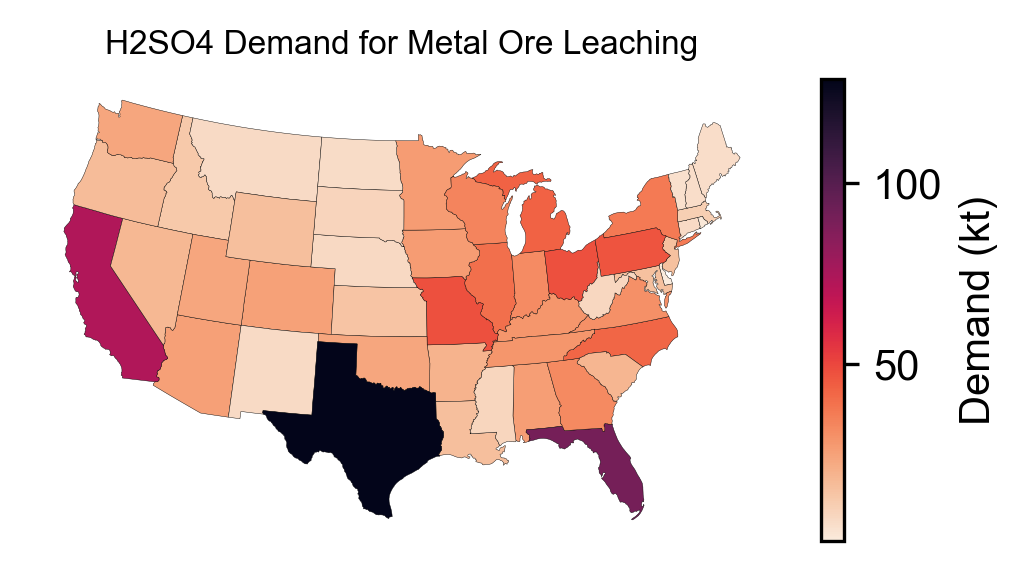

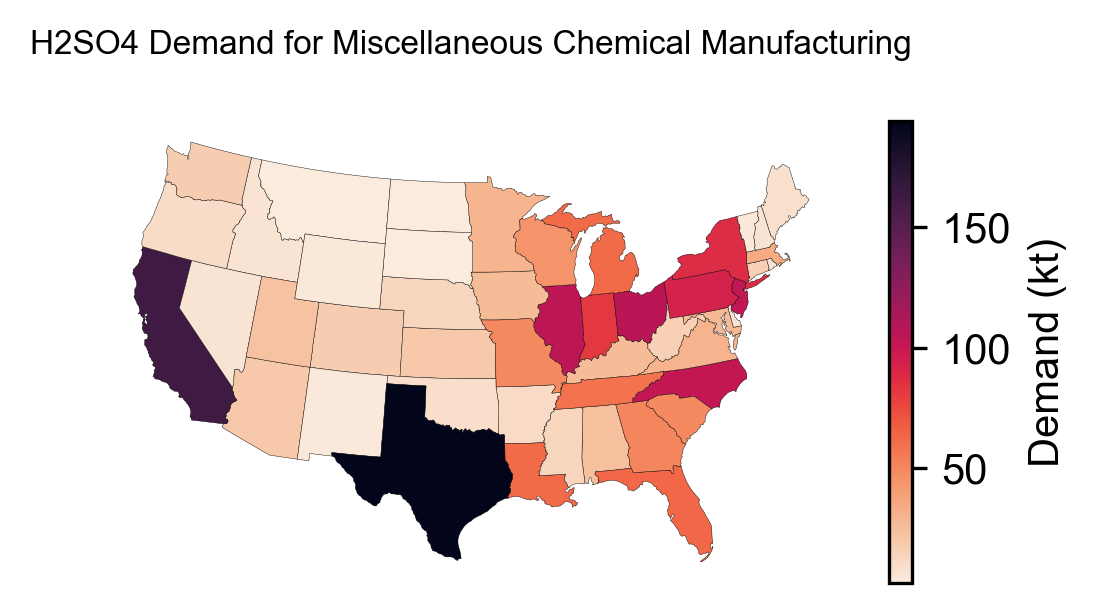

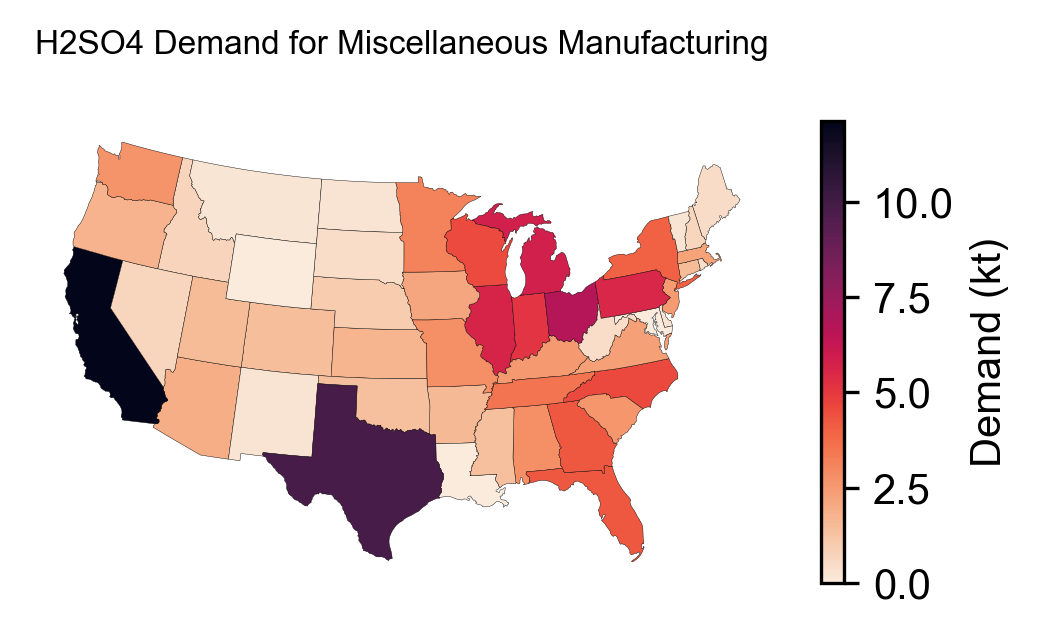

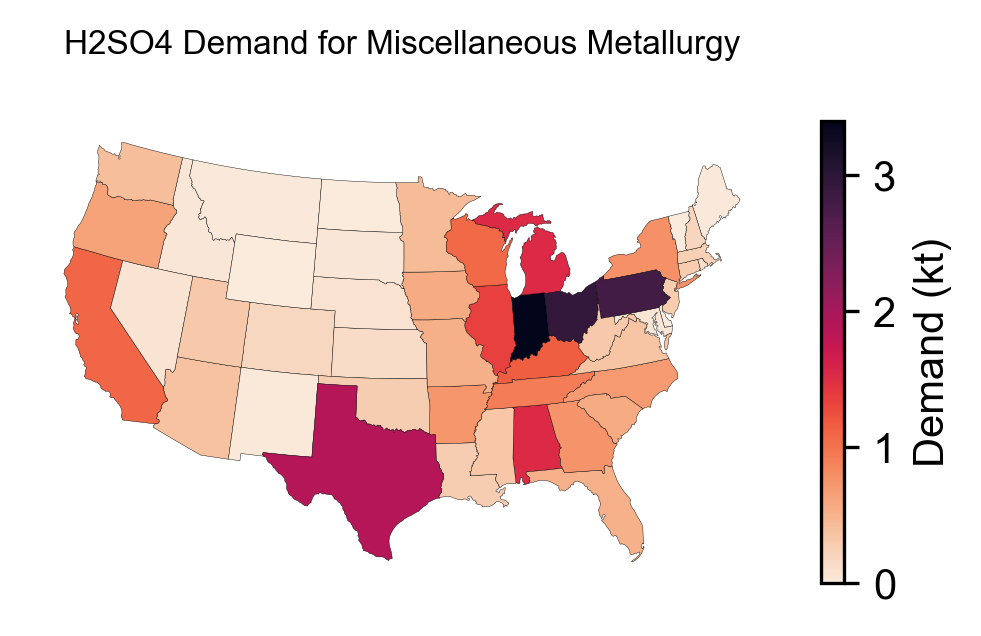

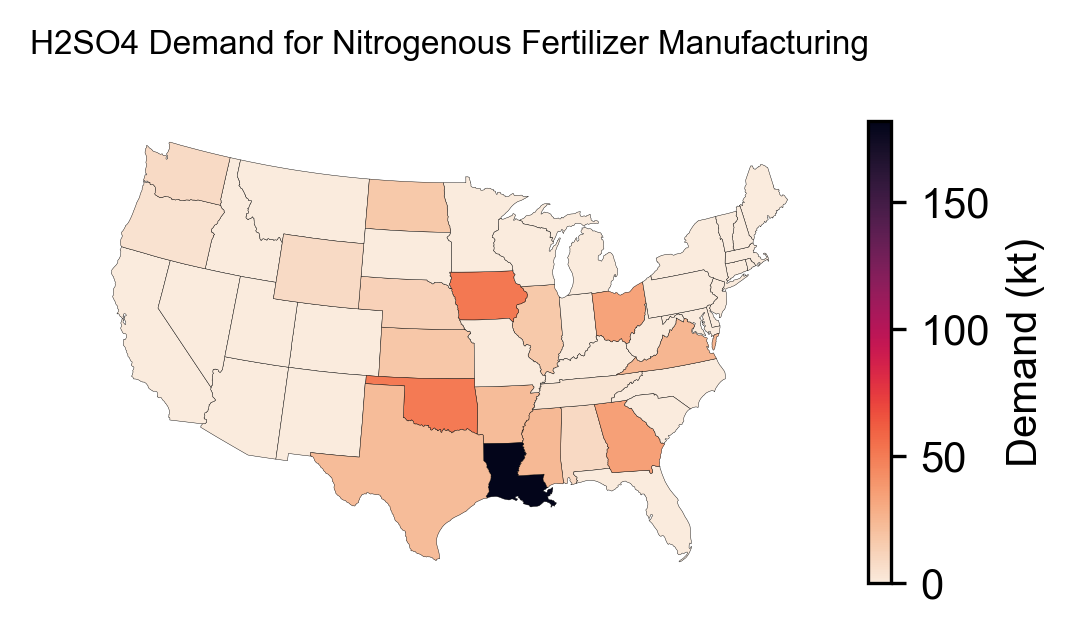

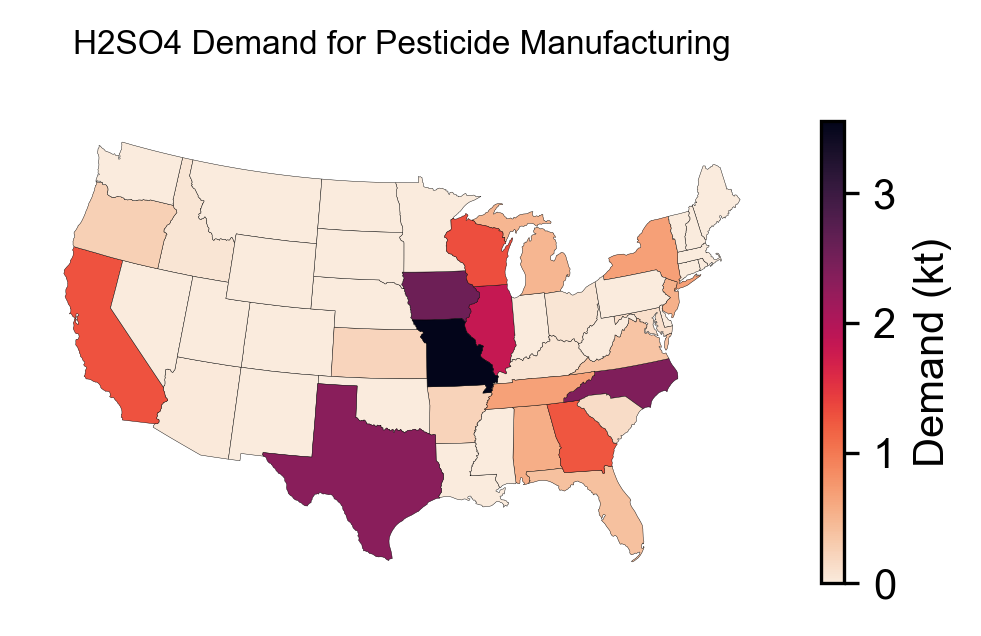

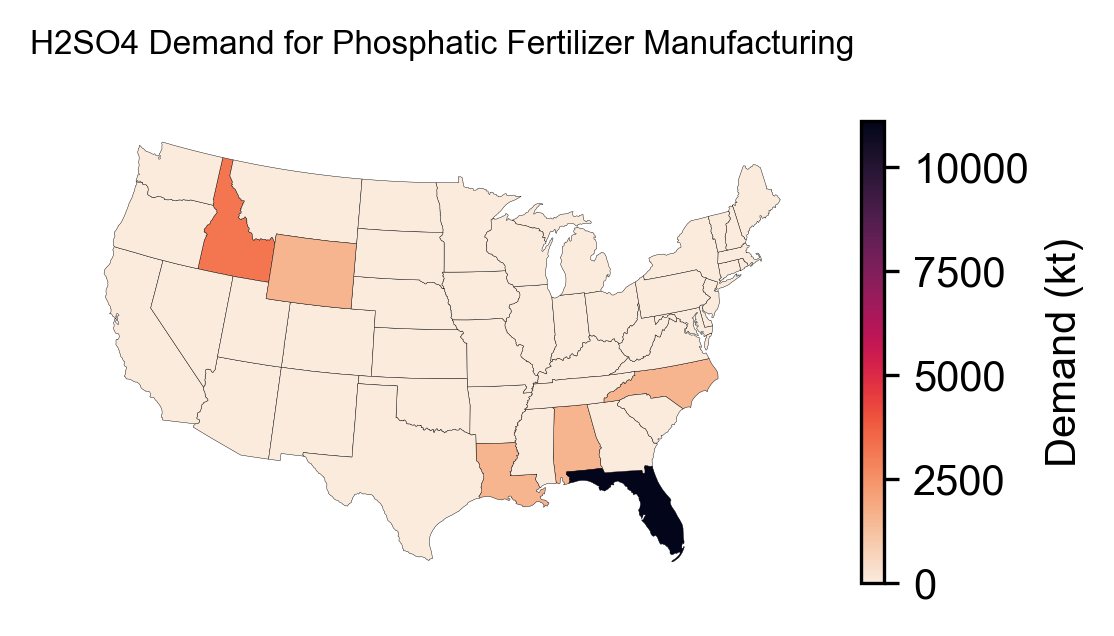

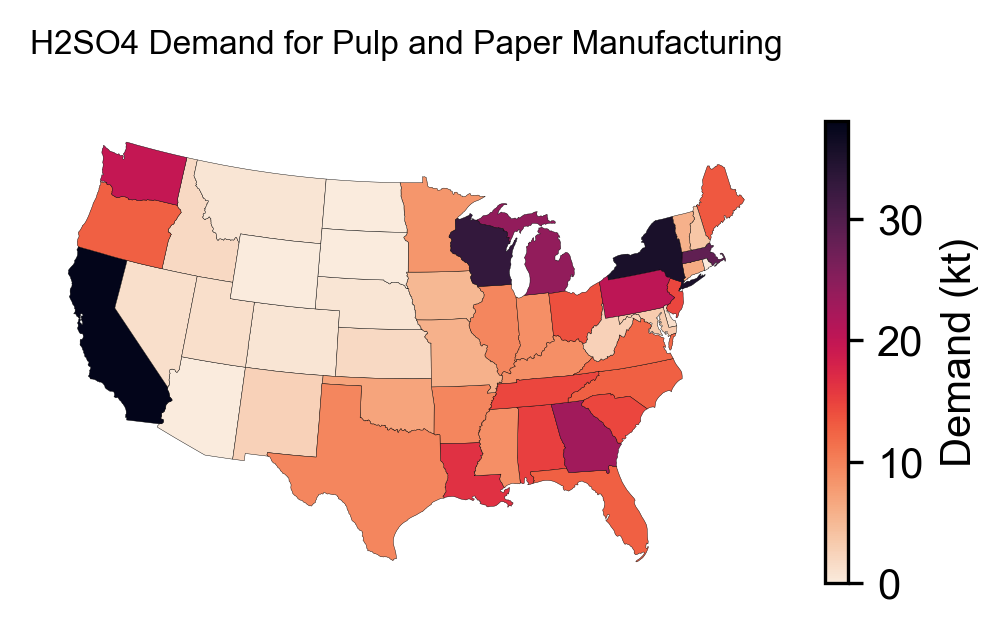

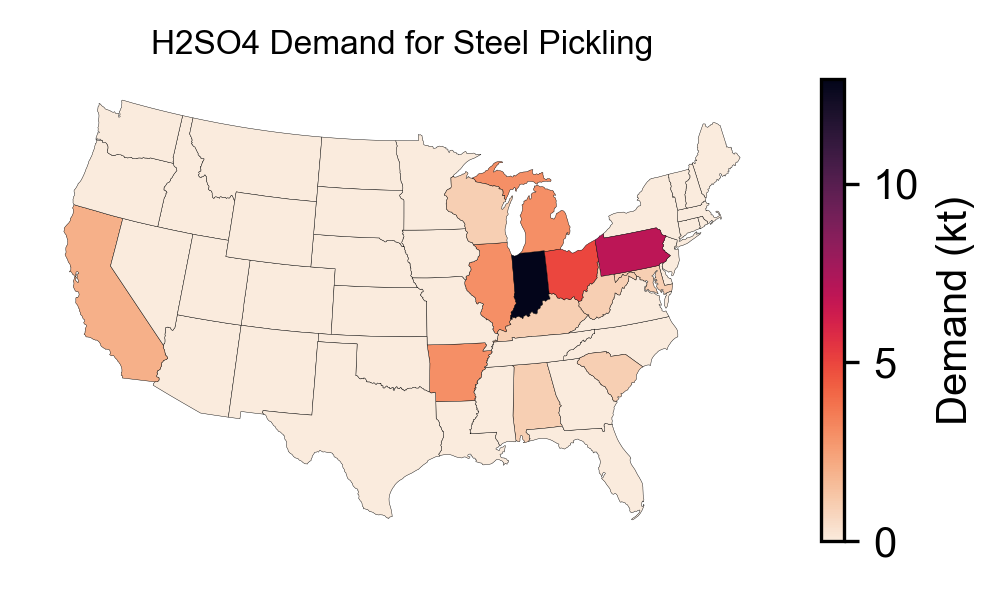

In [120]:
demand = 25035 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Potash (K2O)

In [121]:
bp = 'K2O'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for K2O:
 - Miscellaneous Chemical Manufacturing (15.0%)
 - Potash Fertilizer Application (85.0%)


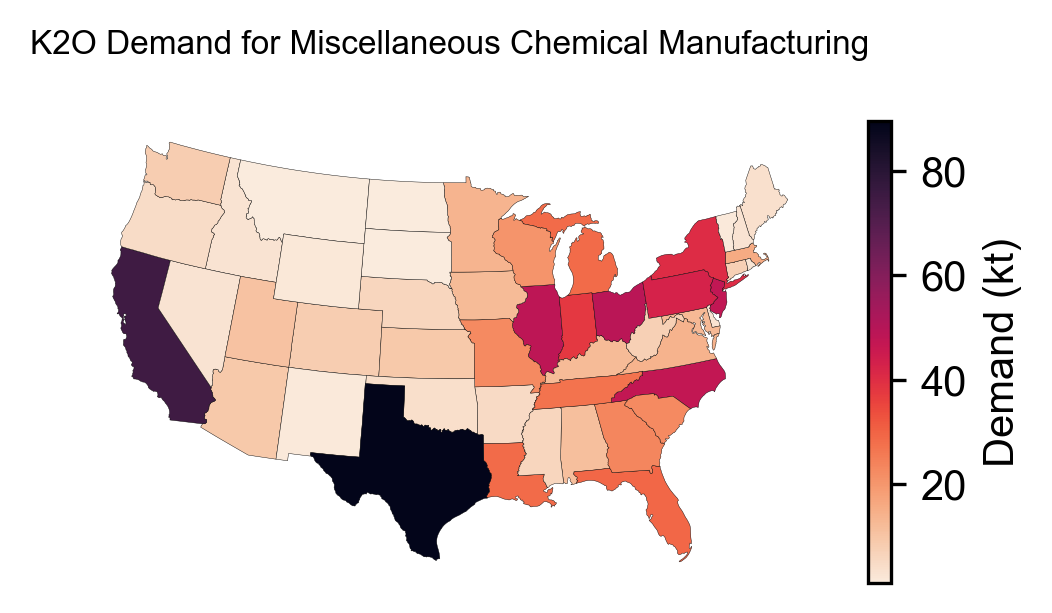

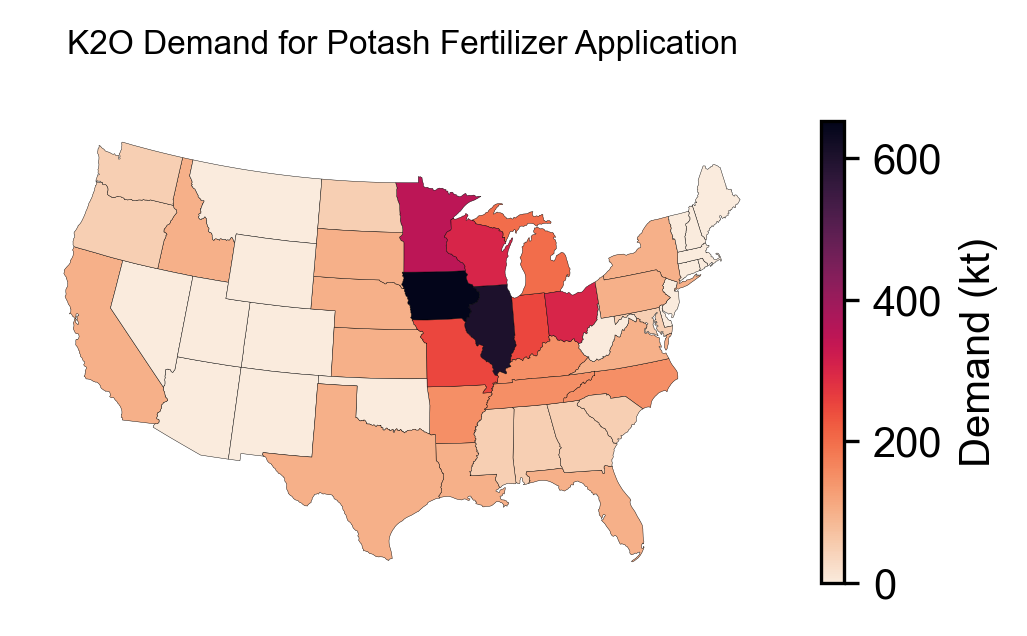

In [122]:
demand = 5900 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Lithium (Li)

In [123]:
bp = 'Li'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for Li:
 - Lithium Battery Manufacturing (88.0%)
 - Other (12.0%)


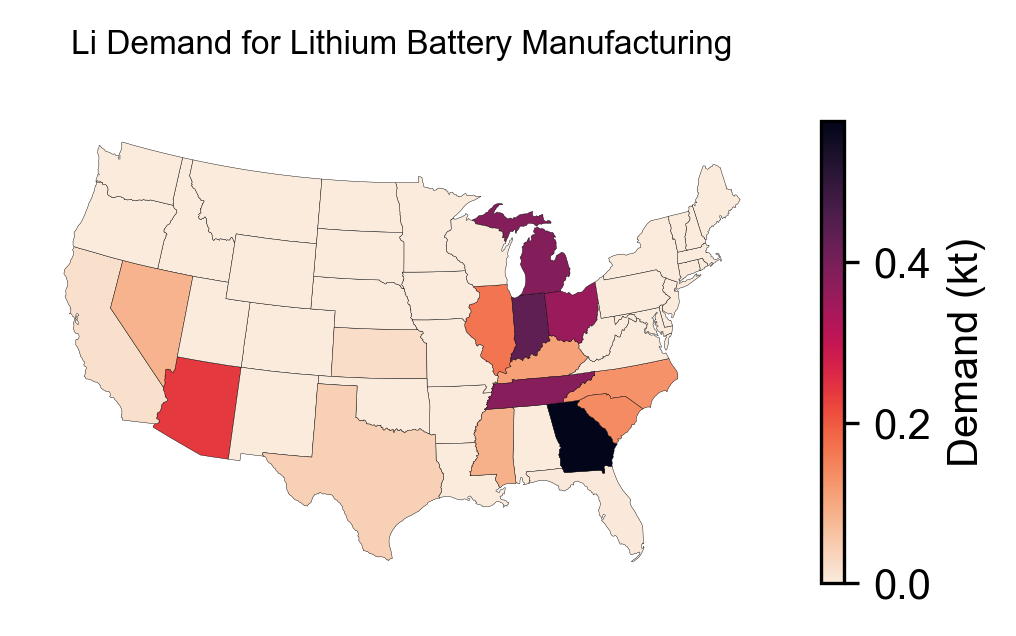

In [124]:
demand = 3.6 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Magnesium Chloride (MgCl2)

In [125]:
bp = 'MgCl2'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for MgCl2:
 - Deicing and Dust Control (100.0%)


Text(0.5, 1.0, 'MgCl2 Demand for Deicing and Dust Control')

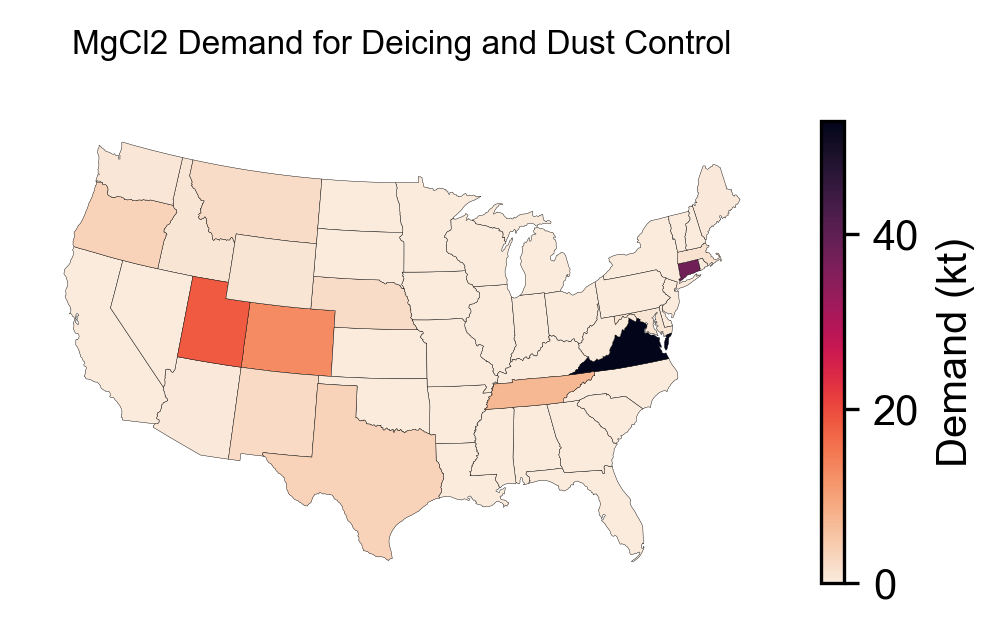

In [126]:
market = 'Deicing and Dust Control'
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'state' # ('state' or 'domestic')
proxy = None

# build state-level demand data series
demand = dict.fromkeys(st_df['STUSPS'], 0)
demand.update({ # (tons)
    'AZ' : 253.76452,
    'AR' : 16.17,
    'CO' : 13963.8831,
    'CT' : 41389.64364,
    'ID' : 968.06446,
    'IN' : 17.22688,
    'KS' : 25.861,
    'ME' : 260.08774,
    'MD' : 1078.65154,
    'MA' : 1438.5118,
    'MN' : 8.80418,
    'MO' : 35.8281,
    'MT' : 2360.62838,
    'NE' : 2302.3,
    'NV' : 2.506075,
    'NH' : 31.47364,
    'NM' : 2678.55,
    'NY' : 120.4962,
    'OR' : 3779.94232,
    'RI' : 2.4464,
    'SD' : 197.32394,
    'TN' : 7976,
    'TX' : 3713.165,
    'UT' : 20194.49922,
    'VT' : 61.22446,
    'VA' : 58440.423,
    'WA' : 822.7626,
    'WI' : 17.0148,
    'WY' : 913.52844
})
demand = pd.Series(demand) / 1102.31 # convert tons to kt
total_withheld = 0 # kt not disclosed due to proprietary information

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy, total_withheld=total_withheld)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Magnesium Hydroxide (Mg(OH)2)

In [127]:
bp = 'Mg(OH)2'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for Mg(OH)2:
 - Miscellaneous Chemical Manufacturing (11.0%)
 - Other (9.0%)
 - Wastewater Treatment (80.0%)


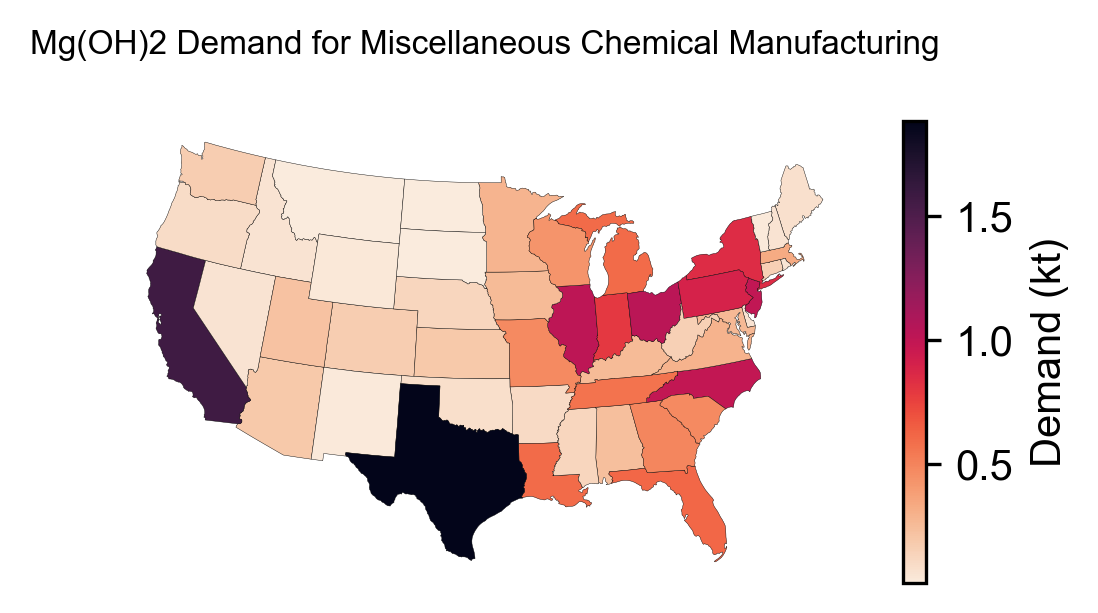

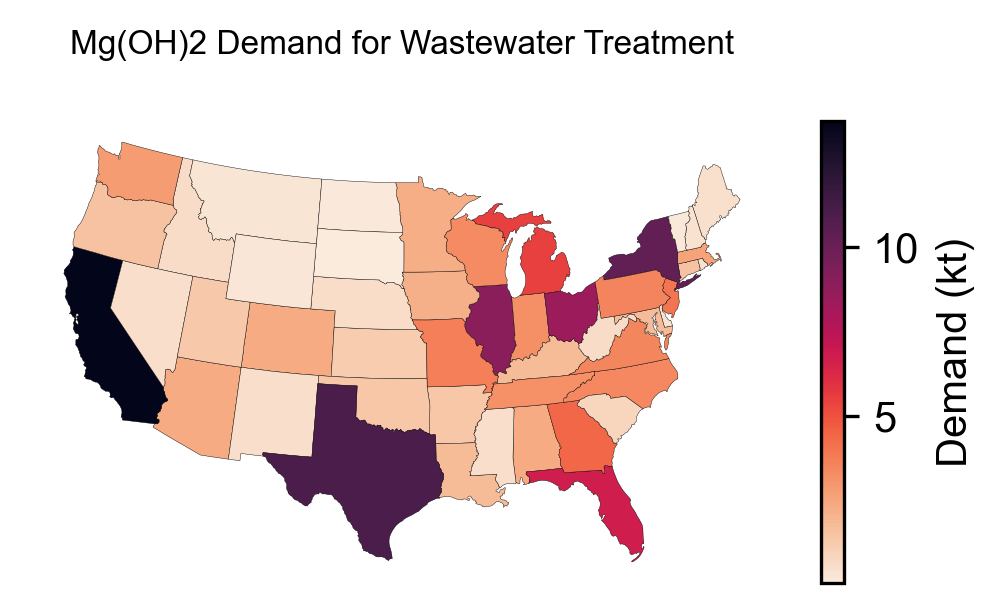

In [128]:
demand = 169 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Magnesium Sulfate (MgSO4)

In [129]:
bp = 'MgSO4'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for MgSO4:
 - Cosmetics and Personal Care Product Manufacturing (48.0%)
 - Miscellaneous Chemical Manufacturing (22.0%)
 - Miscellaneous Fertilizer Application (10.0%)
 - Other (8.0%)
 - Pulp and Paper Manufacturing (12.0%)


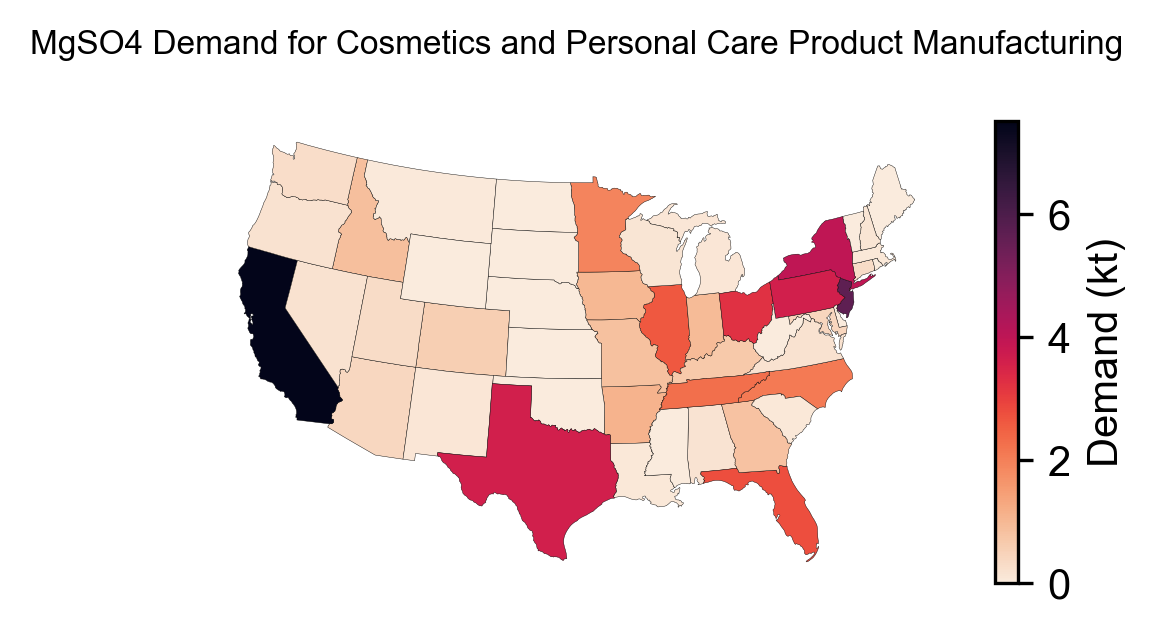

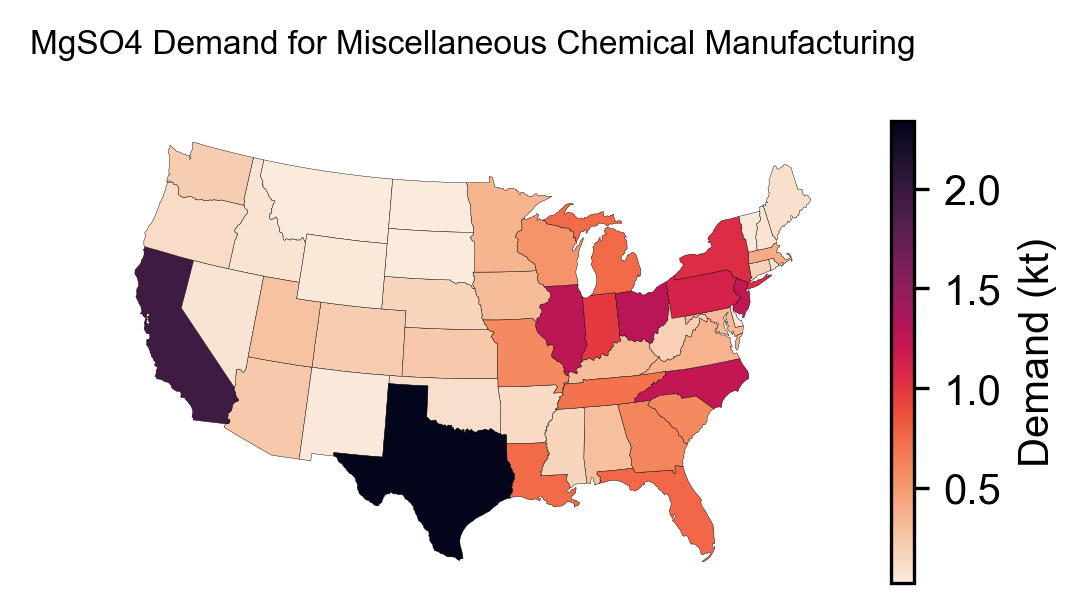

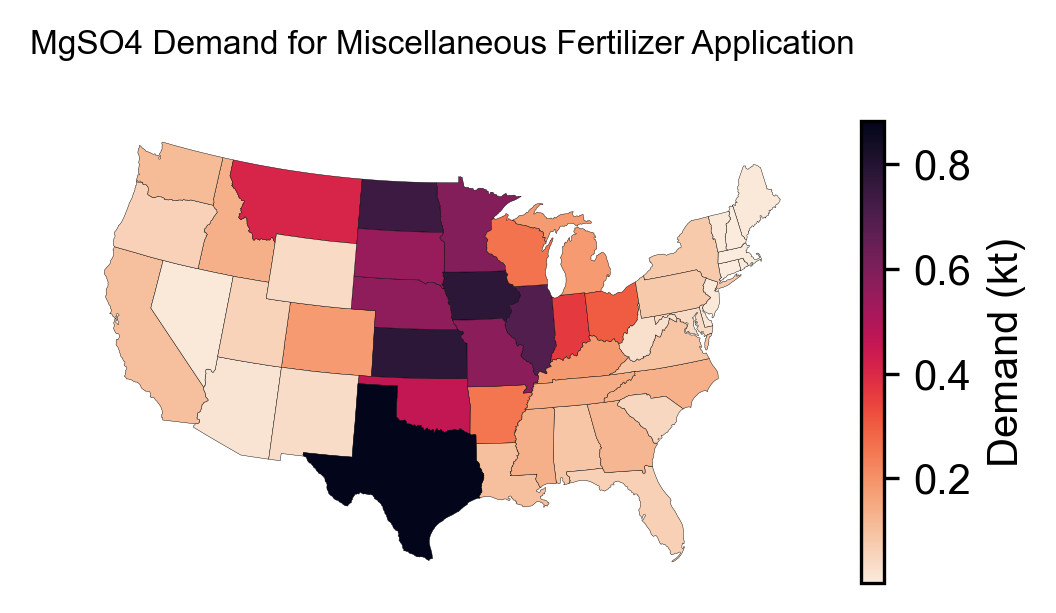

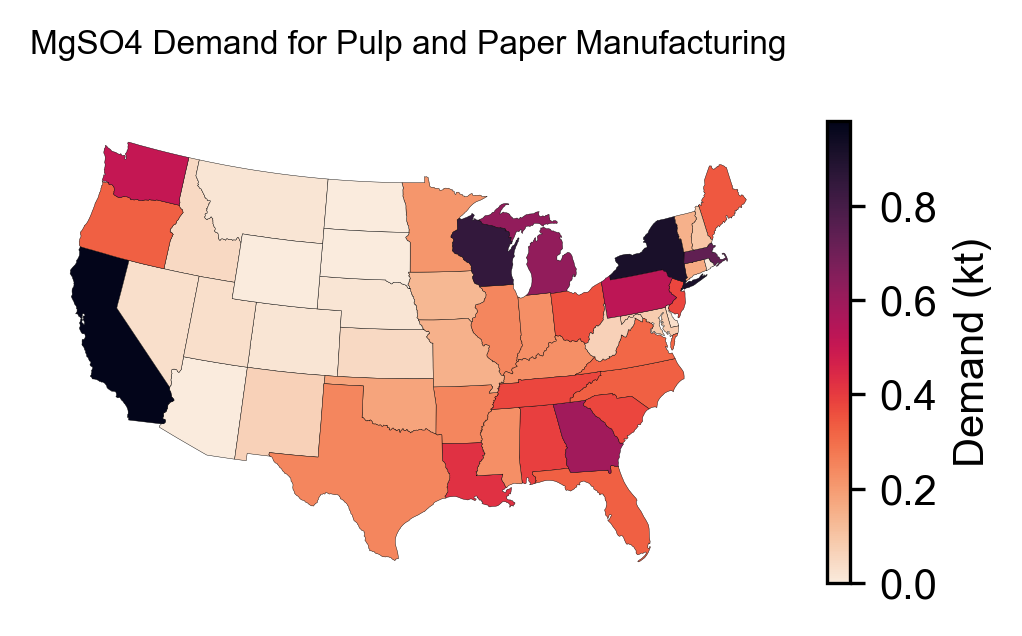

In [130]:
demand =  105 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Sodium Chloride (NaCl)

In [131]:
bp = 'NaCl'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for NaCl:
 - Deicing and Dust Control (37.0%)
 - Miscellaneous Chemical Manufacturing (42.0%)
 - Other (21.0%)


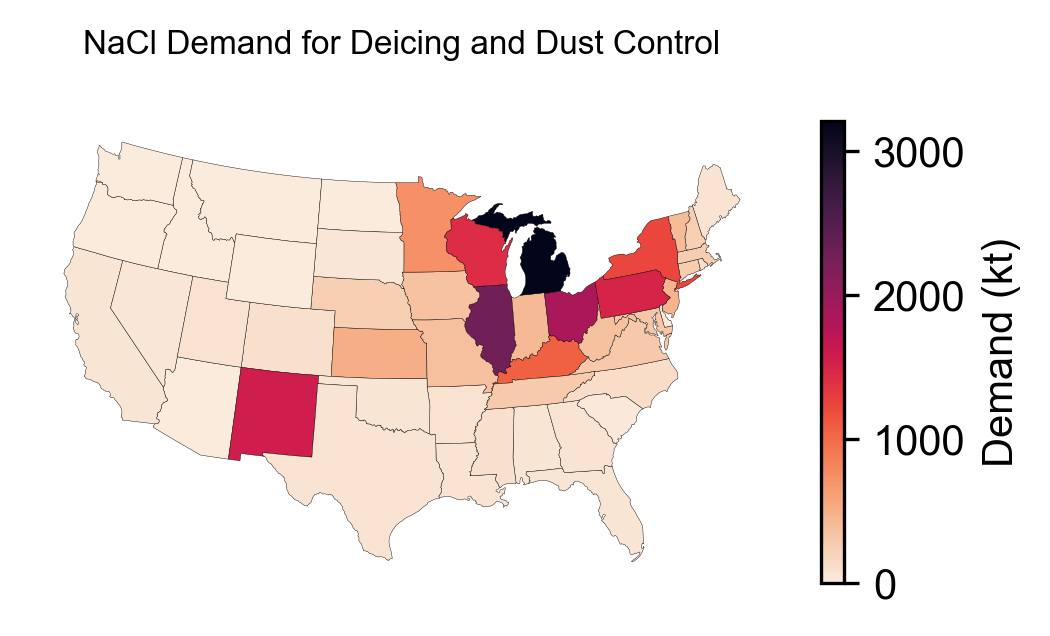

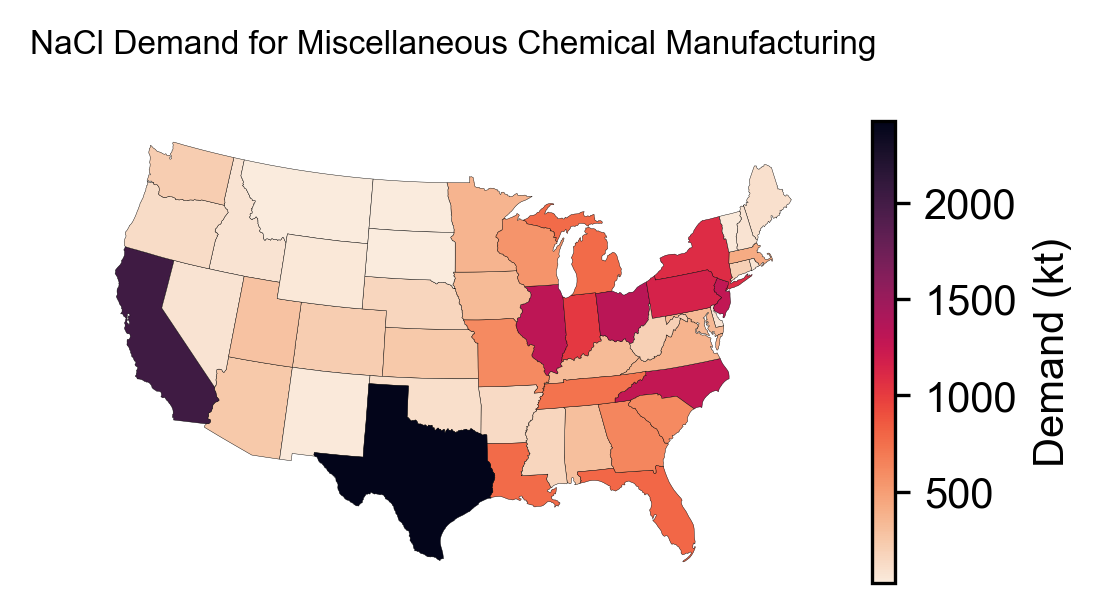

In [132]:
demand =  57000 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Soda Ash (Na2CO3)

In [133]:
bp = 'Na2CO3'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for Na2CO3:
 - Drinking Water Treatment (1.0%)
 - Flue Gas Desulfurization (4.0%)
 - Glass Manufacturing (45.0%)
 - Miscellaneous Chemical Manufacturing (33.0%)
 - Other (16.0%)
 - Pulp and Paper Manufacturing (1.0%)


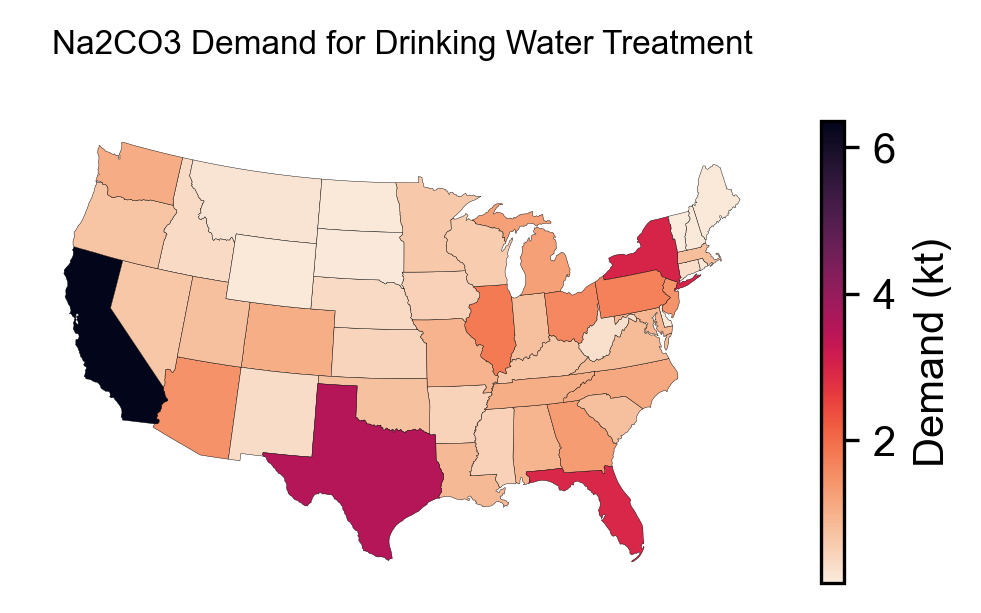

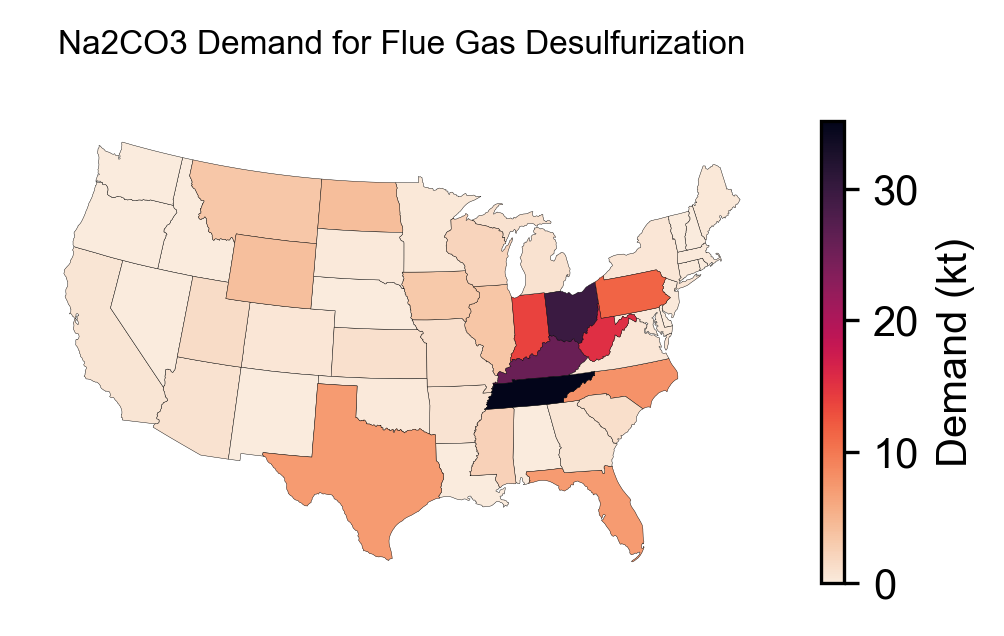

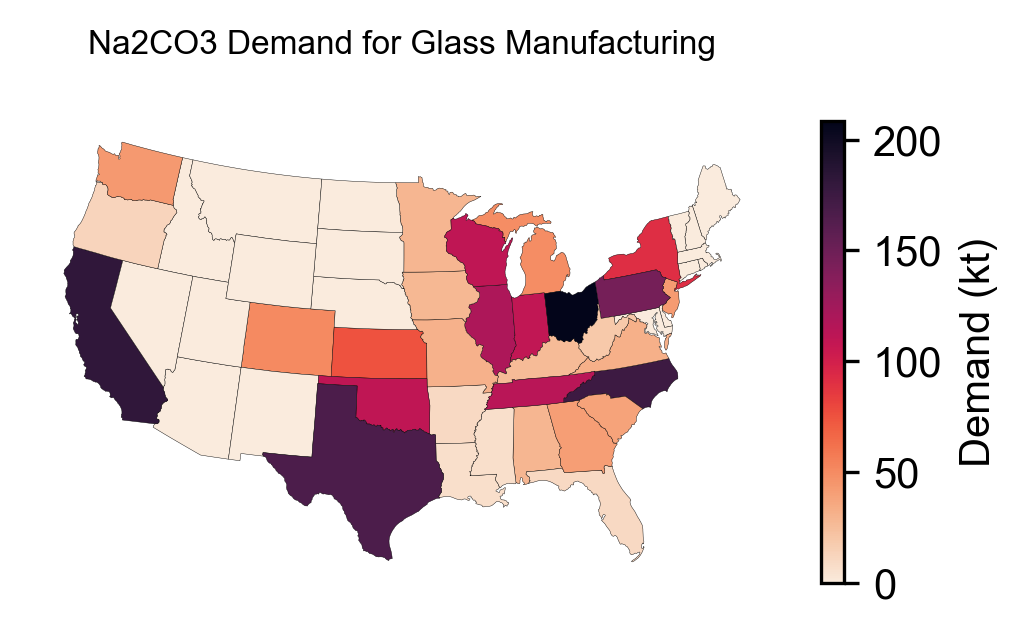

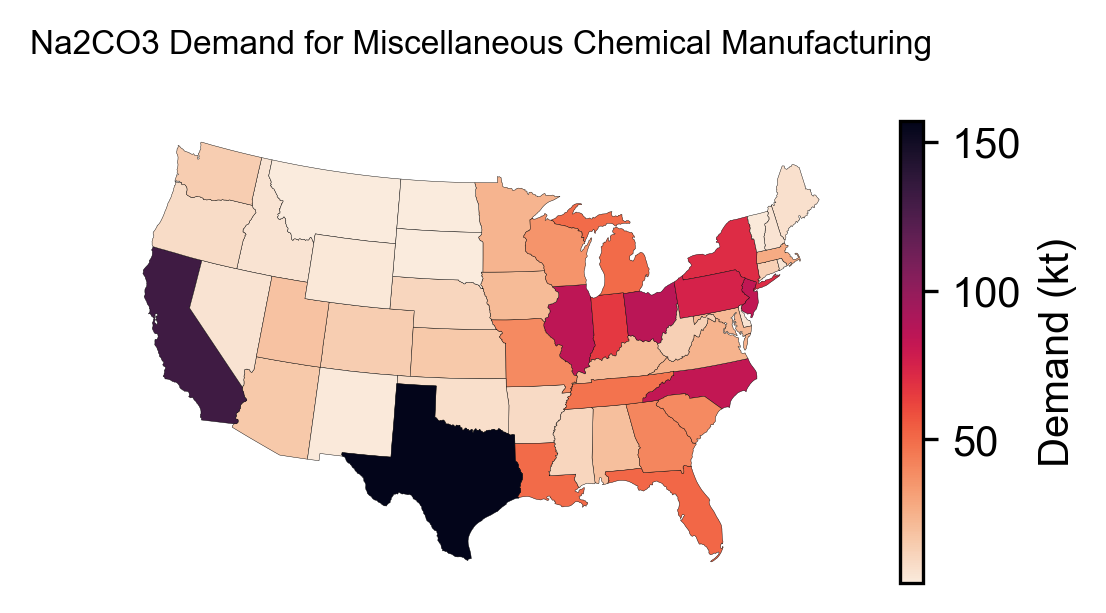

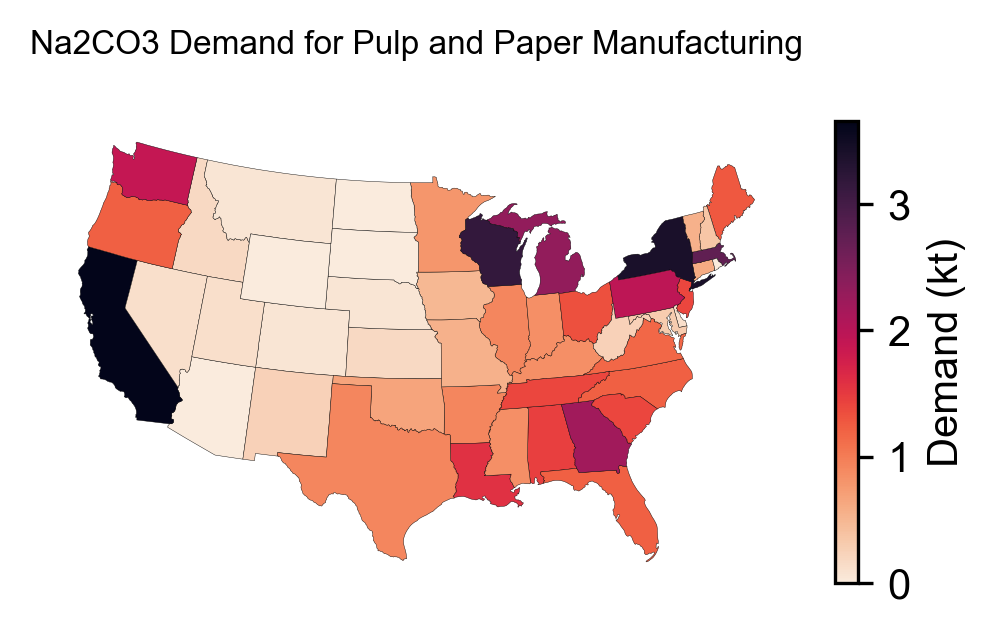

In [134]:
demand =  4700 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Caustic Soda (NaOH)

In [135]:
bp = 'NaOH'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for NaOH:
 - Drinking Water Treatment (3.0%)
 - Miscellaneous Chemical Manufacturing (45.0%)
 - Other (30.0%)
 - Pulp and Paper Manufacturing (22.0%)


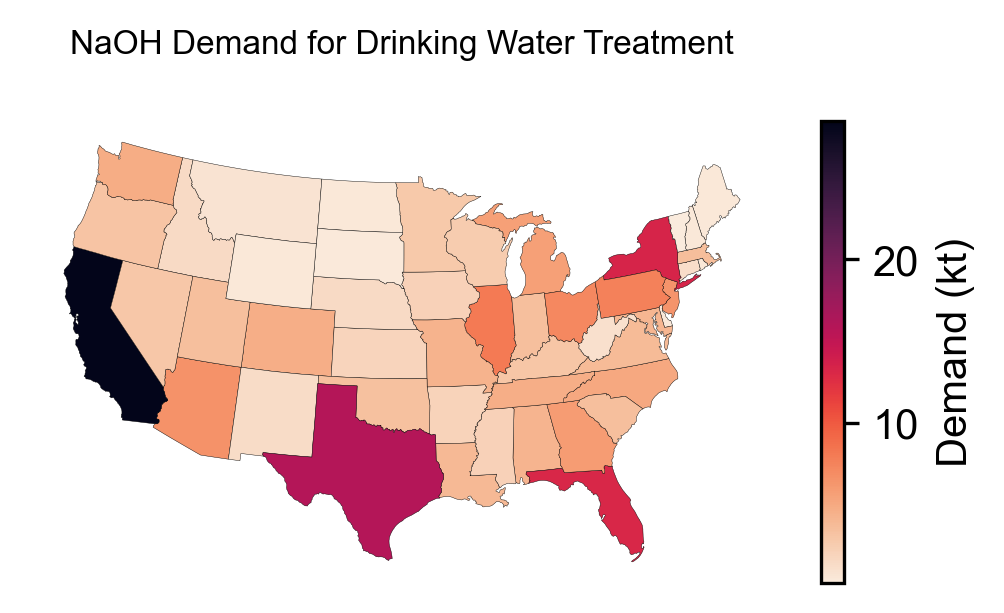

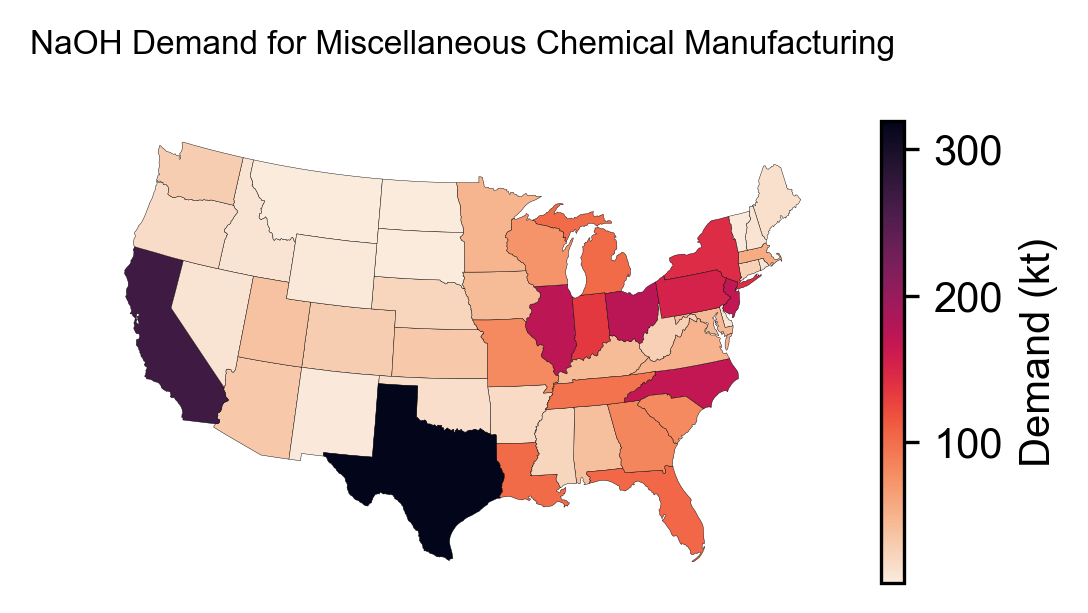

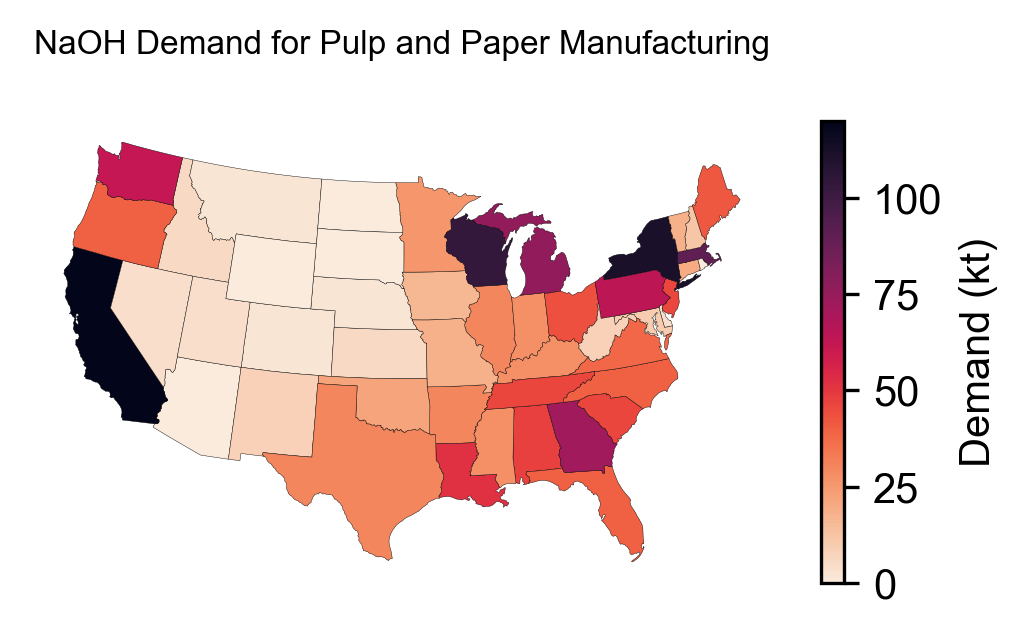

In [136]:
demand =  7013 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Ammonia (NH3)

In [137]:
bp = 'NH3'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for NH3:
 - Miscellaneous Chemical Manufacturing (12.0%)
 - Nitrogenous Fertilizer Application (21.0%)
 - Nitrogenous Fertilizer Manufacturing (67.0%)


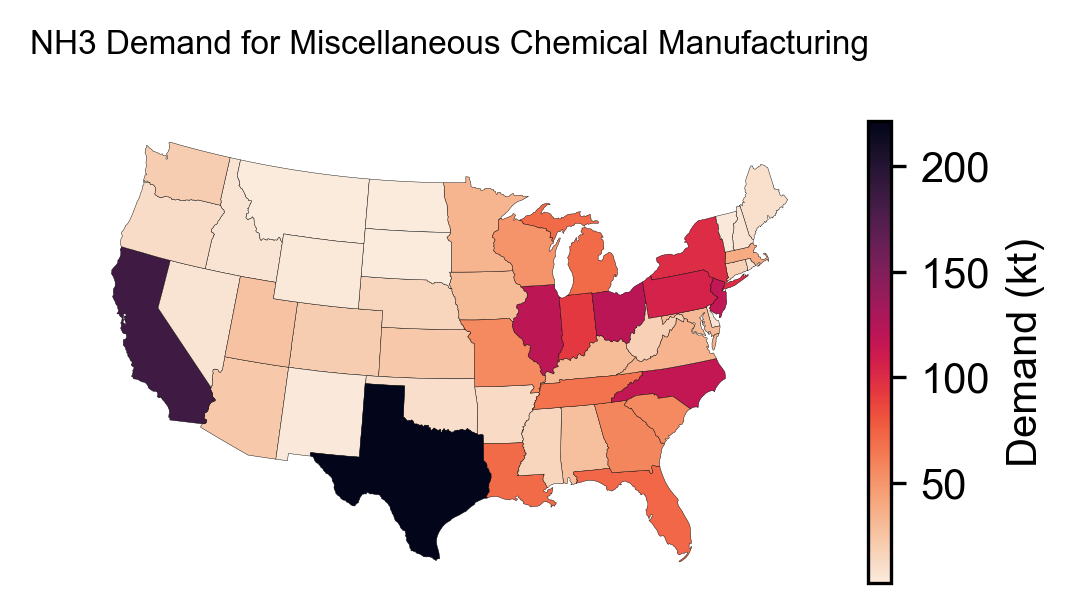

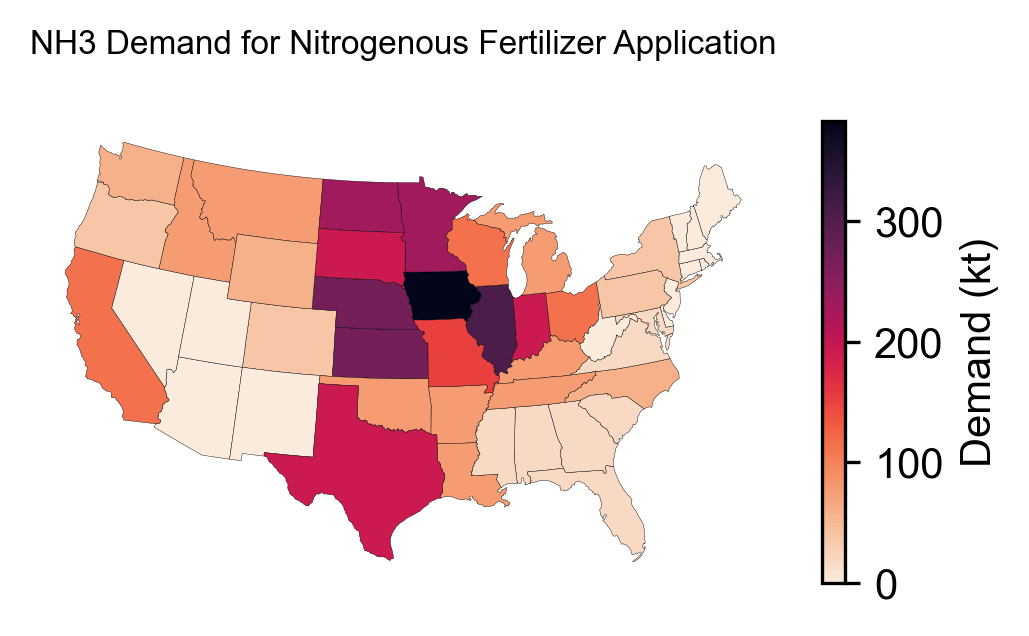

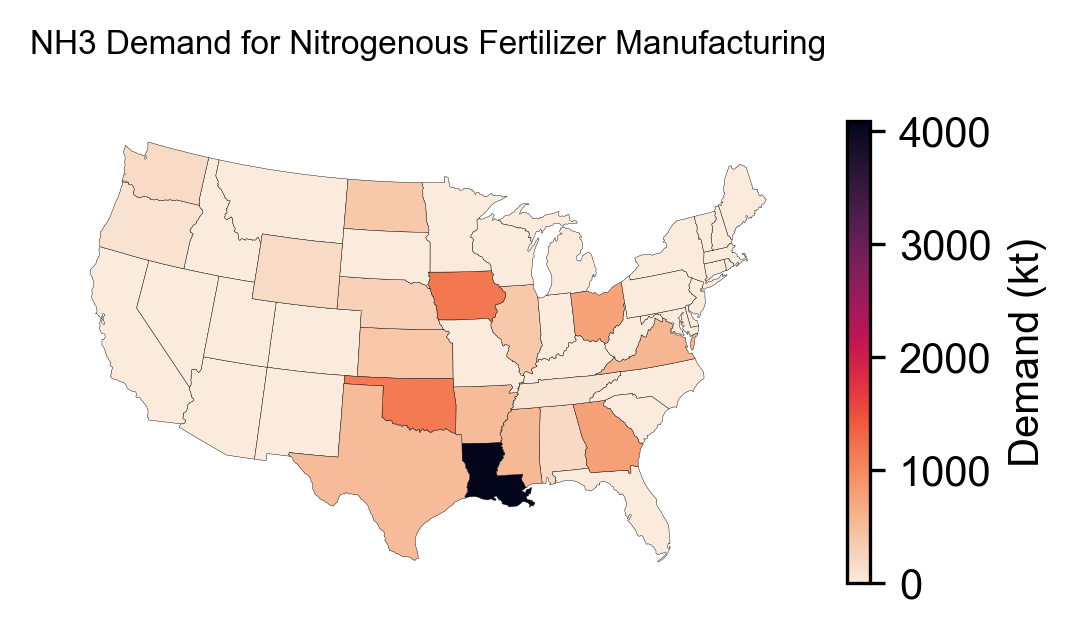

In [138]:
demand =  15000 * Formula('NH3').mass/Formula('N').mass # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Ammonium Hydroxide (NH4OH)

In [139]:
bp = 'NH4OH'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for NH4OH:
 - Nitrogenous Fertilizer Application (nan%)
 - Other (nan%)


Text(0.5, 1.0, 'NH4OH Demand for Nitrogenous Fertilizer Application')

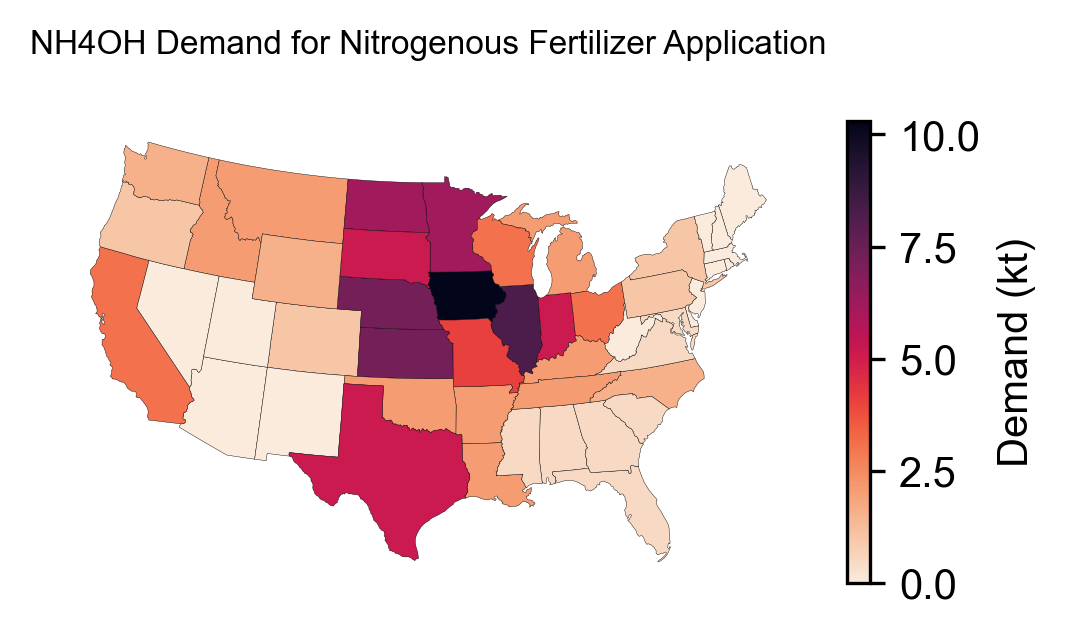

In [140]:
market = 'Nitrogenous Fertilizer Application'
demand =  103 # kt
specificity = 'bp-market' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
proxy = market_to_proxy_dict[market]

state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

# plot map of state-level demand
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')
st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Phosphates (P2O5)

In [141]:
bp = 'P2O5'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for P2O5:
 - Other (5.0%)
 - Phosphoric Acid Manufacturing (95.0%)


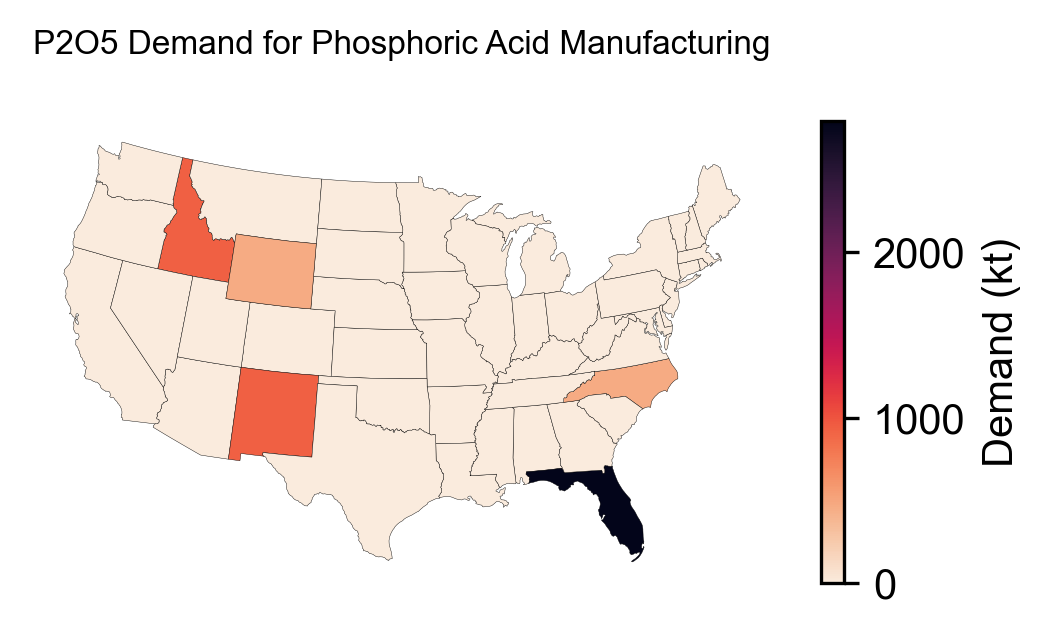

In [142]:
demand =  5880 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)

# Celestite

In [147]:
bp = 'SrSO4'

# identify markets for byproduct
bp_markets = market_df[(market_df['byproduct'] == bp)]['end_use_category'].values
print(f'End-Use Categories for {bp}:')
for market in bp_markets:
    print(f' - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_of_demand"].values[0]:.1f}%)')

demand_dict[bp] = dict.fromkeys(bp_markets, None)

End-Use Categories for SrSO4:
 - Miscellaneous Manufacturing (28.0%)
 - Oil and Gas Drilling (65.0%)
 - Other (7.0%)


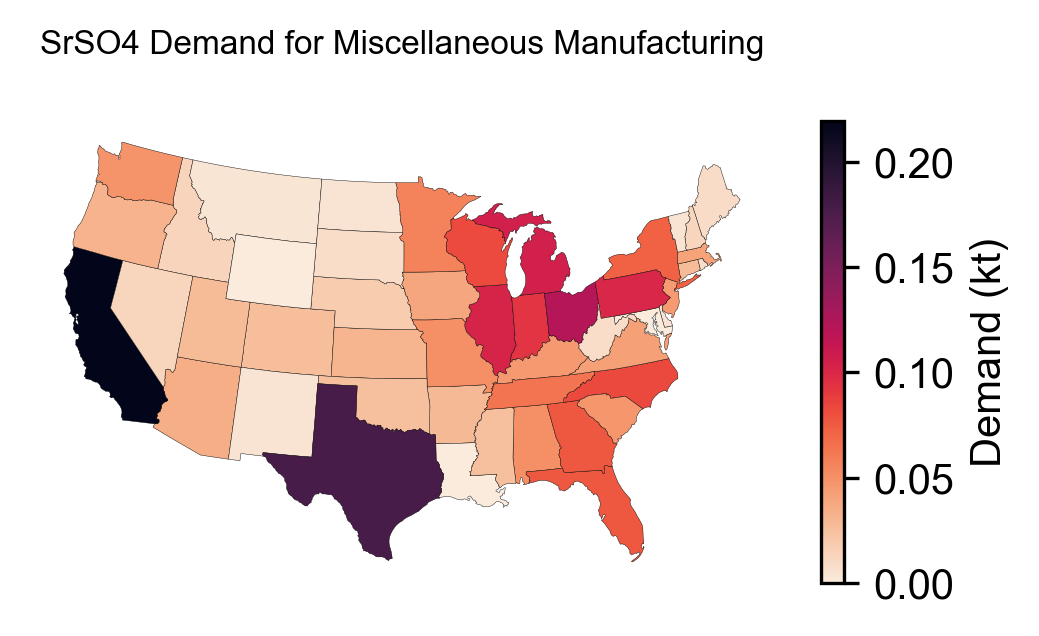

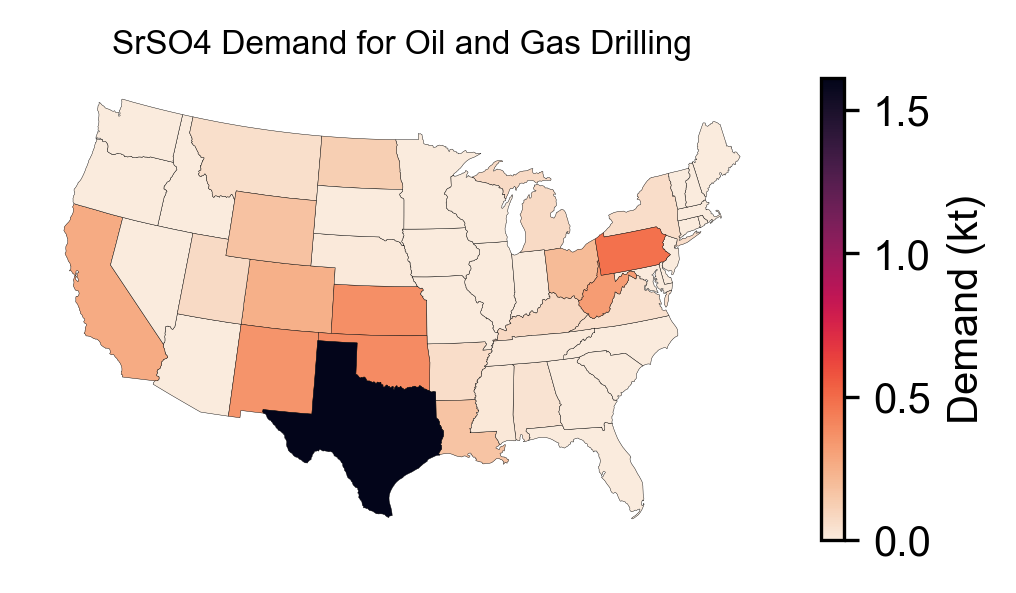

In [148]:
demand =  8.1 # kt
specificity = 'bp' # ('bp' or 'bp-market')
resolution = 'domestic' # ('state' or 'domestic')
for market in bp_markets:
    if market == 'Other':
        continue
    proxy = market_to_proxy_dict[market]
    state_demand = calculate_state_demand(bp, market, demand, specificity, resolution, proxy=proxy)
    demand_dict[bp][market] = pd.DataFrame({'byproduct': bp, 'market': market, 'state_alpha': state_demand.index, 'demand_kt': state_demand.values})

    # plot map of state-level demand
    fig, ax = plt.subplots(figsize=(4,2))
    ax.axis('off')
    st_df['demand_kt'] = st_df['STUSPS'].map(state_demand)
    st_df.plot(column='demand_kt', cmap='rocket_r', linewidth=0.1, ax=ax,edgecolor='black', legend=True, legend_kwds={'label': "Demand (kt)"})
    ax.set_title(f'{bp} Demand for {market}', fontsize=8)